In [1]:
# ── CINVIE 2026 — progressive adoption of residential PV and PV+BESS in Punta Arenas ──
# ── 1. Imports and workflow controls ──
from pathlib import Path
import gc
import importlib

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import display

import config

config = importlib.reload(config)
config.configure_runtime_output()


In [2]:
# ── Workflow controls ────────────────────────────────────────────────────────
# Set True now to add S5. Existing scenarios are skipped because OVERWRITE_RESULTS=False.
RUN_SIMULATIONS = False
OVERWRITE_RESULTS = False

# Model year and weather year: CINVIE is a 2025 snapshot.
MODEL_YEAR = 2025
WEATHER_YEAR = 2025

# Case inputs
CASE_FOLDER = "input_punta_arenas"
BASE_CASE_NAME = "punta_arenas_cinvie"
RESIDENTIAL_ZONE = "punta_arenas_centro"

# ERA5 / atlite
CUTOUT_CASE_NAME = "magallanes"
CUTOUT_FILE = f"{CUTOUT_CASE_NAME}_{WEATHER_YEAR}.nc"
VRE_PROFILE_METHOD = "atlite_technology"
WIND_TURBINE = "Vestas_V112_3MW"
SOLAR_PANEL = "CSi"
SOLAR_ORIENTATION = "latitude_optimal"

# Solver
SOLVER_NAME = "gurobi"
TIME_LIMIT = 2000
MIP_GAP = 0.02
THREADS = 4
FALLBACK_TO_HIGHS = False
PREPARE_CUTOUT = False

# CINVIE does not use these modules.
ENABLE_HEAT = False
ENABLE_HYDROGEN = False
ENABLE_PTX = False

# Output
OUTPUT_ROOT = Path("output") / "output_punta_arenas_cinvie"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
HOURLY_DIR = OUTPUT_ROOT / "hourly"

for folder in [OUTPUT_ROOT, TABLE_DIR, FIGURE_DIR, HOURLY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SUMMARY_CSV = TABLE_DIR / "cinvie_2025_adoption_pathway_summary.csv"

# ── Paper figure settings: aligned with the main Punta Arenas notebook ──────
PAPER_DPI = 300

CM_TO_INCH = 1 / 2.54
WORD_DOUBLE_COL_IN = 16.0 * CM_TO_INCH
FIGSIZE_2COL = (WORD_DOUBLE_COL_IN, 3.35)
FIGSIZE_PAPER_2X2 = (WORD_DOUBLE_COL_IN, 4.95)
FIGSIZE_2COL_LARGE = (7.2, 5.6)

FONT_SIZE_BASE = 9
FONT_SIZE_SMALL = 8
FONT_SIZE_LABEL = 9
FONT_SIZE_PANEL = 9

plt.rcParams.update({
    "font.size": FONT_SIZE_BASE,
    "axes.labelsize": FONT_SIZE_BASE,
    "axes.titlesize": FONT_SIZE_BASE,
    "xtick.labelsize": FONT_SIZE_SMALL,
    "ytick.labelsize": FONT_SIZE_SMALL,
    "legend.fontsize": FONT_SIZE_SMALL,
})

TECH_COLORS = {
    "wind": "#5bbcff",
    "solar": "#ffd54f",
    "solar_pv": "#ffd54f",
    "ocgt": "#b85c5c",
    "gas": "#b85c5c",
    "bess": "#9966cc",
    "slack": "#d32f2f",
}

DEMAND_COLOR = "#4c78a8"
GRID_ALPHA = 0.25


def panel_label(ax, label: str, x: float = 0.015, y: float = 0.965):
    ax.text(
        x, y, label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=FONT_SIZE_PANEL,
        fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1.5},
        zorder=20,
    )


def finish_axis(ax, xlabel=None, ylabel=None):
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=GRID_ALPHA)
    ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)
    return ax


def save_paper_figure(fig, filename: str):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=PAPER_DPI, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path


paths = config.get_case_paths(CASE_FOLDER)

print("Config:", Path(config.__file__).resolve())
print("Case folder:", CASE_FOLDER)
print("Output:", OUTPUT_ROOT)


Config: C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\config.py
Case folder: input_punta_arenas
Output: output\output_punta_arenas_cinvie


In [3]:
# ── 2. Progressive PV → PV+BESS adoption pathway ──
# ── Household-system assumptions ─────────────────────────────────────────────
PV_KW_PER_HOME = 5.0
BESS_KW_PER_HOME = 5.0
BESS_KWH_PER_HOME = 10.0

# Censo 2024 household count used only to express adoption levels as percentages.
TOTAL_HOUSEHOLDS = 49_571


def _mw_from_homes(n_homes: int, kw_per_home: float) -> float:
    return n_homes * kw_per_home / 1_000.0


def _mwh_from_homes(n_homes: int, kwh_per_home: float) -> float:
    return n_homes * kwh_per_home / 1_000.0


def _scenario(
    code: str,
    label: str,
    pv_homes: int,
    bess_homes: int = 0,
    pathway_stage: str = "",
    is_pathway: bool = True,
    counterfactual_for: str = "",
) -> dict:
    if bess_homes > pv_homes:
        raise ValueError("BESS households cannot exceed PV households.")

    pv_mw = _mw_from_homes(pv_homes, PV_KW_PER_HOME)
    bess_mw = _mw_from_homes(bess_homes, BESS_KW_PER_HOME)
    bess_mwh = _mwh_from_homes(bess_homes, BESS_KWH_PER_HOME)

    return {
        "code": code,
        "label": label,
        "pathway_stage": pathway_stage,
        "is_pathway": is_pathway,
        "counterfactual_for": counterfactual_for,
        "pv_homes": int(pv_homes),
        "bess_homes": int(bess_homes),
        # Retained for compatibility with existing summary logic.
        "n_prosumers": int(pv_homes),
        "pv_penetration_pct": 100.0 * pv_homes / TOTAL_HOUSEHOLDS,
        "bess_share_of_pv_pct": (100.0 * bess_homes / pv_homes) if pv_homes > 0 else 0.0,
        "pv_mw": pv_mw,
        "bess_mw": bess_mw,
        "bess_mwh": bess_mwh,
    }


# ── Main adoption pathway ────────────────────────────────────────────────────
PATHWAY_SCENARIOS = [
    _scenario("BASE", "S0 — Baseline", 0, 0, pathway_stage="S0"),
    _scenario("S1_PV5000", "S1 — 5,000 PV", 5_000, 0, pathway_stage="S1"),
    _scenario(
        "S2_PV10000_BESS1000",
        "S2 — 10,000 PV + 1,000 BESS",
        10_000, 1_000, pathway_stage="S2"
    ),
    _scenario(
        "S3_PV20000_BESS5000",
        "S3 — 20,000 PV + 5,000 BESS",
        20_000, 5_000, pathway_stage="S3"
    ),
    _scenario(
        "S4_PV40000_BESS20000",
        "S4 — 40,000 PV + 20,000 BESS",
        40_000, 20_000, pathway_stage="S4"
    ),
    _scenario(
        "S5_PV40000_BESS40000",
        "S5 — 40,000 PV + 40,000 BESS",
        40_000, 40_000, pathway_stage="S5"
    ),
]

# ── PV-only counterfactuals at the BESS stages ───────────────────────────────
COUNTERFACTUAL_SCENARIOS = [
    _scenario(
        "CF_PV10000",
        "CF — 10,000 PV only",
        10_000, 0,
        is_pathway=False,
        counterfactual_for="S2_PV10000_BESS1000",
    ),
    _scenario(
        "CF_PV20000",
        "CF — 20,000 PV only",
        20_000, 0,
        is_pathway=False,
        counterfactual_for="S3_PV20000_BESS5000",
    ),
    _scenario(
        "CF_PV40000",
        "CF — 40,000 PV only",
        40_000, 0,
        is_pathway=False,
        counterfactual_for="S4_PV40000_BESS20000;S5_PV40000_BESS40000",
    ),
]

SCENARIOS = PATHWAY_SCENARIOS + COUNTERFACTUAL_SCENARIOS
SCENARIO_ORDER = [s["code"] for s in SCENARIOS]
SCENARIO_LABELS = {s["code"]: s["label"] for s in SCENARIOS}
PATHWAY_CODES = [s["code"] for s in PATHWAY_SCENARIOS]

scenario_table = pd.DataFrame(SCENARIOS)
display(
    scenario_table[
        [
            "code", "label", "pv_homes", "bess_homes",
            "pv_penetration_pct", "bess_share_of_pv_pct",
            "pv_mw", "bess_mw", "bess_mwh", "is_pathway"
        ]
    ].round(2)
)


,code,label,pv_homes,bess_homes,pv_penetration_pct,bess_share_of_pv_pct,pv_mw,bess_mw,bess_mwh,is_pathway
0,BASE,S0 — Baseline,0,0,0.00,0.0,0.0,0.0,0.0,True
1,S1_PV5000,"S1 — 5,000 PV",5000,0,10.09,0.0,25.0,0.0,0.0,True
2,S2_PV10000_BESS1000,"S2 — 10,000 PV + 1,000 BESS",10000,1000,20.17,10.0,50.0,5.0,10.0,True
3,S3_PV20000_BESS5000,"S3 — 20,000 PV + 5,000 BESS",20000,5000,40.35,25.0,100.0,25.0,50.0,True
4,S4_PV40000_BESS20000,"S4 — 40,000 PV + 20,000 BESS",40000,20000,80.69,50.0,200.0,100.0,200.0,True
5,S5_PV40000_BESS40000,"S5 — 40,000 PV + 40,000 BESS",40000,40000,80.69,100.0,200.0,200.0,400.0,True
6,CF_PV10000,"CF — 10,000 PV only",10000,0,20.17,0.0,50.0,0.0,0.0,False
7,CF_PV20000,"CF — 20,000 PV only",20000,0,40.35,0.0,100.0,0.0,0.0,False
8,CF_PV40000,"CF — 40,000 PV only",40000,0,80.69,0.0,200.0,0.0,0.0,False


In [4]:
# ── 3. Build a single-node fixed-capacity 2025 system ──
PV_TEMPLATE_ASSET_ID = "pv_residential_flexible_punta_arenas_centro"
CINVIE_PV_ASSET_ID = "pv_residential_cinvie_punta_arenas_centro"
CINVIE_BESS_ASSET_ID = "bess_2h_cinvie_punta_arenas_centro"


def _enabled_mask(df: pd.DataFrame) -> pd.Series:
    if "enabled" not in df.columns:
        return pd.Series(True, index=df.index)
    return df["enabled"].astype(str).str.strip().str.lower().isin(
        ["true", "1", "yes", "y"]
    )


def _fixed_2025_mask(df: pd.DataFrame) -> pd.Series:
    """Select fixed/existing assets commissioned no later than MODEL_YEAR."""
    ctype = (
        df.get("commissioning_type", pd.Series("", index=df.index))
        .astype(str)
        .str.strip()
        .str.lower()
    )
    fixed = ctype.isin(["fixed", "existing", "committed", "commissioned", "exogenous"])

    fixed_year = pd.to_numeric(
        df.get("fixed_commissioning_year", pd.Series(np.nan, index=df.index)),
        errors="coerce",
    )
    available_year = pd.to_numeric(
        df.get("available_from_year", pd.Series(np.nan, index=df.index)),
        errors="coerce",
    )

    year_ok = (
        (fixed_year.isna() | (fixed_year <= MODEL_YEAR))
        & (available_year.isna() | (available_year <= MODEL_YEAR))
    )
    return _enabled_mask(df) & fixed & year_ok


def build_cinvie_nodes() -> pd.DataFrame:
    """Return only the aggregated Punta Arenas electrical node."""
    nodes_df = config.load_nodes_from_csv(paths["csv_nodes"])
    if nodes_df is None or nodes_df.empty:
        raise ValueError("nodes.csv could not be loaded.")

    node = nodes_df[nodes_df["zone"].astype(str).eq(RESIDENTIAL_ZONE)].copy()
    if node.empty:
        raise KeyError(
            f"Node '{RESIDENTIAL_ZONE}' was not found in nodes.csv."
        )

    # Exactly one electrical node in CINVIE.
    return node.reset_index(drop=True)


def build_cinvie_inputs(scenario: dict):
    """Build fixed 2025 generator/storage tables for the single-node CINVIE case."""
    capacity_all = config.load_generator_capacity_from_csv(paths["csv_capacity"])
    storage_all = config.load_storage_capacity_from_csv(paths["csv_storage"])

    if capacity_all is None or capacity_all.empty:
        raise ValueError("generators_capacity.csv could not be loaded.")
    if storage_all is None:
        raise ValueError("storage_capacity.csv could not be loaded.")

    capacity_all = capacity_all.copy()
    storage_all = storage_all.copy()

    # Save the residential PV row only as a physical/template definition.
    pv_template_mask = capacity_all["asset_id"].astype(str).eq(PV_TEMPLATE_ASSET_ID)
    if not pv_template_mask.any():
        raise KeyError(
            f"Residential PV template '{PV_TEMPLATE_ASSET_ID}' "
            "was not found in generators_capacity.csv."
        )
    pv_template = capacity_all.loc[pv_template_mask].iloc[0].copy()

    # ── Existing 2025 generation only ──────────────────────────────────────
    # This deliberately removes every flexible/candidate expansion option.
    capacity_df = capacity_all.loc[_fixed_2025_mask(capacity_all)].copy()

    # Single-node aggregation: existing Cabo Negro/Punta Arenas assets are
    # electrically represented at the Punta Arenas node.
    capacity_df["zone"] = RESIDENTIAL_ZONE

    # ── Exogenous residential PV ───────────────────────────────────────────
    if float(scenario["pv_mw"]) > 0:
        pv_row = pv_template.copy()
        pv_row["asset_id"] = CINVIE_PV_ASSET_ID
        pv_row["generator"] = "pv_residential_cinvie"
        pv_row["zone"] = RESIDENTIAL_ZONE
        pv_row["technology"] = "solar"
        pv_row["cost_key"] = "solar_residential_new"
        pv_row["installed_capacity"] = float(scenario["pv_mw"])
        pv_row["p_min_mw"] = 0.0
        pv_row["available_from_year"] = MODEL_YEAR
        pv_row["earliest_commissioning_year"] = MODEL_YEAR
        pv_row["fixed_commissioning_year"] = MODEL_YEAR
        pv_row["commissioning_type"] = "fixed"
        pv_row["enabled"] = True
        capacity_df = pd.concat(
            [capacity_df, pd.DataFrame([pv_row])],
            ignore_index=True,
        )

    # ── Existing storage only ──────────────────────────────────────────────
    # There is currently no existing 2025 BESS; future BESS candidates are removed.
    storage_df = storage_all.loc[_fixed_2025_mask(storage_all)].copy()
    if not storage_df.empty:
        storage_df["zone"] = RESIDENTIAL_ZONE

    # ── Exogenous residential BESS ─────────────────────────────────────────
    if float(scenario["bess_mw"]) > 0:
        new_row = {column: np.nan for column in storage_all.columns}
        new_row.update({
            "asset_id": CINVIE_BESS_ASSET_ID,
            "storage": "bess_2h_cinvie",
            "zone": RESIDENTIAL_ZONE,
            "technology": "bess",
            "cost_key": "bess_2h",
            "installed_power_mw": float(scenario["bess_mw"]),
            "p_nom_max_mw": float(scenario["bess_mw"]),
            "max_hours": float(scenario["bess_mwh"]) / float(scenario["bess_mw"]),
            "available_from_year": MODEL_YEAR,
            "earliest_commissioning_year": MODEL_YEAR,
            "fixed_commissioning_year": MODEL_YEAR,
            "commissioning_type": "fixed",
            "enabled": True,
            "initial_soc_fraction": np.nan,
            "final_soc_fraction": np.nan,
            "cyclic_state_of_charge": True,
        })
        storage_df = pd.concat(
            [storage_df, pd.DataFrame([new_row])],
            ignore_index=True,
        )

    # Explicit safety checks: CINVIE must contain no expandable rows.
    if (
        capacity_df.get("commissioning_type", pd.Series(dtype=str))
        .astype(str).str.lower().isin(["flexible", "candidate", "extendable", "expandable", "endogenous"])
        .any()
    ):
        raise RuntimeError("Expandable generator row survived the CINVIE filter.")

    if (
        storage_df.get("commissioning_type", pd.Series(dtype=str))
        .astype(str).str.lower().isin(["flexible", "candidate", "extendable", "expandable", "endogenous"])
        .any()
    ):
        raise RuntimeError("Expandable storage row survived the CINVIE filter.")

    return capacity_df.reset_index(drop=True), storage_df.reset_index(drop=True)


# Preview the aggregated node and largest PV+BESS case.
nodes_preview = build_cinvie_nodes()
cap_preview, storage_preview = build_cinvie_inputs(SCENARIOS[-1])

display(nodes_preview)
display(cap_preview[[
    "asset_id", "generator", "zone", "technology", "cost_key",
    "installed_capacity", "commissioning_type"
]])
display(storage_preview[[
    "asset_id", "storage", "zone", "technology", "cost_key",
    "installed_power_mw", "max_hours", "commissioning_type"
]])


,zone,annual_mean_mw,annual_heat_mean_mw,existing_gas_boiler_mw,installed_heat_pump_mw,allow_heat_pump,heat_pump_cop,gas_boiler_efficiency,lat,lon,enabled
0,punta_arenas_centro,38,20,28,0,True,3,0.9,-53.163,-70.917,True


,asset_id,generator,zone,technology,cost_key,installed_capacity,commissioning_type
0,wind_existing_cabo_negro,wind_existing,punta_arenas_centro,wind,wind_existing,2.55,fixed
1,ocgt_existing_punta_arenas_centro,ocgt_existing,punta_arenas_centro,ocgt,ocgt_existing,80.00,fixed
2,pv_residential_cinvie_punta_arenas_centro,pv_residential_cinvie,punta_arenas_centro,solar,solar_residential_new,200.00,fixed


,asset_id,storage,zone,technology,cost_key,installed_power_mw,max_hours,commissioning_type


In [5]:
# ── 4. Run the 2025 single-node scenarios ──
def _sum_generator_carrier(net, carrier: str) -> pd.Series:
    ids = net.generators.index[
        net.generators["carrier"].astype(str).str.lower().eq(carrier.lower())
    ].tolist()
    if not ids:
        return pd.Series(0.0, index=net.snapshots)
    return net.generators_t.p.reindex(columns=ids, fill_value=0.0).sum(axis=1)


def _sum_storage_power(net, carrier: str = "bess") -> pd.Series:
    ids = net.storage_units.index[
        net.storage_units["carrier"].astype(str).str.lower().eq(carrier.lower())
    ].tolist()
    if not ids:
        return pd.Series(0.0, index=net.snapshots)
    return net.storage_units_t.p.reindex(columns=ids, fill_value=0.0).sum(axis=1)


def _sum_storage_soc(net, carrier: str = "bess") -> pd.Series:
    ids = net.storage_units.index[
        net.storage_units["carrier"].astype(str).str.lower().eq(carrier.lower())
    ].tolist()
    if not ids:
        return pd.Series(0.0, index=net.snapshots)
    return net.storage_units_t.state_of_charge.reindex(columns=ids, fill_value=0.0).sum(axis=1)


def _annual_co2_tons(net) -> float:
    if "co2_emissions" not in net.carriers.columns:
        return 0.0

    carrier_ef = net.carriers["co2_emissions"].fillna(0.0)
    carrier = net.generators["carrier"].astype(str)
    efficiency = net.generators["efficiency"].replace(0, np.nan).fillna(1.0)
    ef_per_mwh_el = carrier.map(carrier_ef).fillna(0.0) / efficiency

    dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)
    return float(dispatch.multiply(ef_per_mwh_el, axis=1).to_numpy().sum())


def _solar_curtailment(net) -> tuple[float, float, float]:
    """Return available, dispatched and curtailed solar energy [MWh]."""
    ids = net.generators.index[
        net.generators["carrier"].astype(str).str.lower().eq("solar")
    ].tolist()

    if not ids:
        return 0.0, 0.0, 0.0

    p_nom = net.generators.loc[ids, "p_nom"].astype(float).copy()
    if "p_nom_opt" in net.generators.columns:
        p_nom = net.generators.loc[ids, "p_nom_opt"].fillna(p_nom).astype(float)

    p_max_pu = net.generators_t.p_max_pu.reindex(columns=ids)
    if p_max_pu.isna().any().any():
        raise ValueError("Solar p_max_pu is missing; curtailment cannot be calculated.")

    available = p_max_pu.multiply(p_nom, axis=1)
    dispatch = net.generators_t.p.reindex(columns=ids, fill_value=0.0).clip(lower=0.0)
    curtailed = (available - dispatch).clip(lower=0.0)

    return (
        float(available.to_numpy().sum()),
        float(dispatch.to_numpy().sum()),
        float(curtailed.to_numpy().sum()),
    )


def _capacity_by_carrier(net, carrier: str) -> float:
    ids = net.generators.index[
        net.generators["carrier"].astype(str).str.lower().eq(carrier.lower())
    ]
    if len(ids) == 0:
        return 0.0
    if "p_nom_opt" in net.generators.columns:
        vals = net.generators.loc[ids, "p_nom_opt"].fillna(net.generators.loc[ids, "p_nom"])
    else:
        vals = net.generators.loc[ids, "p_nom"]
    return float(vals.astype(float).sum())


def summarize_scenario(net, scenario: dict) -> tuple[dict, pd.DataFrame]:
    load = net.loads_t.p_set.sum(axis=1)
    wind = _sum_generator_carrier(net, "wind")
    solar = _sum_generator_carrier(net, "solar")
    thermal = _sum_generator_carrier(net, "ocgt")
    slack = _sum_generator_carrier(net, "slack")

    bess_p = _sum_storage_power(net, "bess")
    bess_discharge = bess_p.clip(lower=0.0)
    bess_charge = (-bess_p.clip(upper=0.0))
    bess_soc = _sum_storage_soc(net, "bess")

    solar_available_mwh, solar_dispatch_mwh, solar_curtailment_mwh = _solar_curtailment(net)

    # v2: Preserve hourly raw resource for residential PV (not curtailed system dispatch).
    # No change to the original PyPSA results, objective or balance constraints.
    if CINVIE_PV_ASSET_ID in net.generators.index:
        g = net.generators.loc[CINVIE_PV_ASSET_ID]
        nom = float(g["p_nom_opt"]) if "p_nom_opt" in g and pd.notna(g["p_nom_opt"]) else float(g["p_nom"])
        pv_available = net.generators_t.p_max_pu[CINVIE_PV_ASSET_ID].astype(float) * nom
    else:
        pv_available = pd.Series(0.0, index=net.snapshots)

    ocgt_ids = net.generators.index[
        net.generators["carrier"].astype(str).str.lower().eq("ocgt")
    ].tolist()
    if ocgt_ids:
        ocgt_mc = net.generators.loc[ocgt_ids, "marginal_cost"].astype(float)
        thermal_operating_cost = float(
            net.generators_t.p[ocgt_ids].clip(lower=0.0).multiply(ocgt_mc, axis=1).to_numpy().sum()
        )
    else:
        thermal_operating_cost = 0.0

    annual_row = {
        **scenario,
        "year": MODEL_YEAR,
        "weather_year": WEATHER_YEAR,
        "objective_usd": float(net.objective),
        "demand_mwh": float(load.sum()),
        "peak_demand_mw": float(load.max()),
        "wind_generation_mwh": float(wind.sum()),
        "solar_generation_mwh": float(solar.sum()),
        "thermal_generation_mwh": float(thermal.sum()),
        "slack_mwh": float(slack.sum()),
        "bess_charge_mwh": float(bess_charge.sum()),
        "bess_discharge_mwh": float(bess_discharge.sum()),
        "solar_available_mwh": solar_available_mwh,
        "solar_curtailment_mwh": solar_curtailment_mwh,
        "solar_curtailment_pct": (
            100.0 * solar_curtailment_mwh / solar_available_mwh
            if solar_available_mwh > 0 else 0.0
        ),
        "co2_tons": _annual_co2_tons(net),
        "thermal_operating_cost_usd": thermal_operating_cost,
        "installed_wind_mw": _capacity_by_carrier(net, "wind"),
        "installed_solar_mw": _capacity_by_carrier(net, "solar"),
        "installed_bess_mw": float(
            net.storage_units.loc[
                net.storage_units["carrier"].astype(str).str.lower().eq("bess"),
                "p_nom",
            ].astype(float).sum()
        ) if len(net.storage_units) else 0.0,
    }

    hourly = pd.DataFrame({
        "demand_mw": load,
        "wind_mw": wind,
        "solar_mw": solar,
        "pv_available_mw": pv_available,  # v2: actual physical PV availability
        "thermal_mw": thermal,
        "slack_mw": slack,
        "bess_charge_mw": bess_charge,
        "bess_discharge_mw": bess_discharge,
        "bess_soc_mwh": bess_soc,
    }, index=pd.DatetimeIndex(net.snapshots))
    hourly.index.name = "timestamp"

    return annual_row, hourly


In [6]:
def run_all_cinvie_scenarios():
    rows = []

    for scenario in SCENARIOS:
        code = scenario["code"]
        hourly_path = HOURLY_DIR / f"{code}_2025.csv"

        if (
            not OVERWRITE_RESULTS
            and hourly_path.exists()
            and SUMMARY_CSV.exists()
        ):
            existing = pd.read_csv(SUMMARY_CSV)
            hit = existing[existing["code"].astype(str).eq(code)]
            if not hit.empty:
                print(f"Skipping existing scenario: {code}")
                rows.append(hit.iloc[-1].to_dict())
                continue

        print(
            f"\n=== {scenario['label']} | "
            f"PV={scenario['pv_mw']:.1f} MW | "
            f"BESS={scenario['bess_mw']:.1f} MW / {scenario['bess_mwh']:.1f} MWh ==="
        )

        nodes_df = build_cinvie_nodes()
        capacity_df, storage_df = build_cinvie_inputs(scenario)

        result = config.run_case(
            year=MODEL_YEAR,
            weather_year=WEATHER_YEAR,
            case_name=f"{BASE_CASE_NAME}_{code}",
            solver_name=SOLVER_NAME,
            vre_profile_method=VRE_PROFILE_METHOD,
            wind_turbine=WIND_TURBINE,
            solar_panel=SOLAR_PANEL,
            solar_orientation=SOLAR_ORIENTATION,
            time_limit=TIME_LIMIT,
            mip_gap=MIP_GAP,
            threads=THREADS,
            prepare_cutout=PREPARE_CUTOUT,
            fallback_to_highs=FALLBACK_TO_HIGHS,
            co2_cap_tons=None,
            enable_hydrogen=ENABLE_HYDROGEN,
            enable_heat=ENABLE_HEAT,
            enable_ptx=ENABLE_PTX,
            nodes_df=nodes_df,
            capacity_df=capacity_df,
            storage_df=storage_df,
            csv_nodes=paths["csv_nodes"],
            csv_interlinks=paths["csv_interlinks"],
            csv_capacity=paths["csv_capacity"],
            csv_storage=paths["csv_storage"],
            csv_hydro_assets=paths["csv_hydro_assets"],
            csv_hydro_inflows=paths["csv_hydro_inflows"],
            csv_hydrogen=paths["csv_hydrogen"],
            csv_ptx_assets=paths["csv_ptx_assets"],
            csv_ptx_monthly_demand=paths["csv_ptx_monthly_demand"],
            csv_costs=paths["csv_costs"],
            csv_general=paths["csv_general"],
            csv_demand=paths["csv_demand"],
            csv_demand_summary=paths["csv_demand_summary"],
            cutout_file=CUTOUT_FILE,
        )

        net = result["network"]
        row, hourly = summarize_scenario(net, scenario)
        rows.append(row)
        hourly.to_csv(hourly_path)

        # Update summary after every completed scenario.
        summary = pd.DataFrame(rows)
        summary.to_csv(SUMMARY_CSV, index=False)

        del hourly
        del net
        result.clear()
        gc.collect()

    return pd.DataFrame(rows)


if RUN_SIMULATIONS:
    scenario_summary = run_all_cinvie_scenarios()
else:
    if not SUMMARY_CSV.exists():
        raise FileNotFoundError(
            f"{SUMMARY_CSV} does not exist. Set RUN_SIMULATIONS=True and run this cell."
        )
    scenario_summary = pd.read_csv(SUMMARY_CSV)

scenario_summary["code"] = pd.Categorical(
    scenario_summary["code"],
    categories=SCENARIO_ORDER,
    ordered=True,
)
scenario_summary = scenario_summary.sort_values("code").reset_index(drop=True)

display(scenario_summary)


,code,label,pathway_stage,is_pathway,counterfactual_for,pv_homes,bess_homes,n_prosumers,pv_penetration_pct,bess_share_of_pv_pct,...,bess_charge_mwh,bess_discharge_mwh,solar_available_mwh,solar_curtailment_mwh,solar_curtailment_pct,co2_tons,thermal_operating_cost_usd,installed_wind_mw,installed_solar_mw,installed_bess_mw
0,BASE,S0 — Baseline,S0,True,NaN,0,0,0,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,140960.459268,1.474257e+07,2.55,0.0,0.0
1,S1_PV5000,"S1 — 5,000 PV",S1,True,NaN,5000,0,5000,10.086543,0.0,...,0.000000,0.000000,28777.753819,0.000000,0.000000,125662.811186,1.314264e+07,2.55,25.0,0.0
2,S2_PV10000_BESS1000,"S2 — 10,000 PV + 1,000 BESS",S2,True,NaN,10000,1000,10000,20.173085,10.0,...,681.756639,606.230057,57555.507638,346.424716,0.601897,110684.294706,1.157609e+07,2.55,50.0,5.0
3,S3_PV20000_BESS5000,"S3 — 20,000 PV + 5,000 BESS",S3,True,NaN,20000,5000,20000,40.346170,25.0,...,11870.582328,10527.753232,115111.015275,15498.755484,13.464181,89693.554278,9.380738e+06,2.55,100.0,25.0
4,S4_PV40000_BESS20000,"S4 — 40,000 PV + 20,000 BESS",S4,True,NaN,40000,20000,40000,80.692340,50.0,...,57662.680441,52040.569098,230222.030550,64012.641047,27.804742,56714.507304,5.931574e+06,2.55,200.0,100.0
5,S5_PV40000_BESS40000,"S5 — 40,000 PV + 40,000 BESS",S5,True,NaN,40000,40000,40000,80.692340,100.0,...,87982.760631,79404.441469,230222.030550,34669.985454,15.059369,42168.448833,4.410252e+06,2.55,200.0,200.0
6,CF_PV10000,"CF — 10,000 PV only",NaN,False,S2_PV10000_BESS1000,10000,0,10000,20.173085,0.0,...,0.000000,0.000000,57555.507638,774.758522,1.346107,111000.291053,1.160914e+07,2.55,50.0,0.0
7,CF_PV20000,"CF — 20,000 PV only",NaN,False,S3_PV20000_BESS5000,20000,0,20000,40.346170,0.0,...,0.000000,0.000000,115111.015275,26626.731359,23.131350,95271.876769,9.964155e+06,2.55,100.0,0.0
8,CF_PV40000,"CF — 40,000 PV only",NaN,False,S4_PV40000_BESS20000;S5_PV40000_BESS40000,40000,0,40000,80.692340,0.0,...,0.000000,0.000000,230222.030550,119766.527501,52.022184,84378.178246,8.824821e+06,2.55,200.0,0.0


In [7]:
# ── 5. System-impact summary ──
summary = scenario_summary.copy()
baseline = summary[summary["code"].astype(str).eq("BASE")].iloc[0]

summary["thermal_reduction_mwh"] = (
    baseline["thermal_generation_mwh"] - summary["thermal_generation_mwh"]
)
summary["thermal_reduction_pct"] = np.where(
    baseline["thermal_generation_mwh"] > 0,
    100.0 * summary["thermal_reduction_mwh"] / baseline["thermal_generation_mwh"],
    np.nan,
)

summary["co2_reduction_tons"] = baseline["co2_tons"] - summary["co2_tons"]
summary["co2_reduction_pct"] = np.where(
    baseline["co2_tons"] > 0,
    100.0 * summary["co2_reduction_tons"] / baseline["co2_tons"],
    np.nan,
)

summary["objective_change_usd"] = summary["objective_usd"] - baseline["objective_usd"]
summary["thermal_cost_saving_usd"] = (
    baseline["thermal_operating_cost_usd"] - summary["thermal_operating_cost_usd"]
)

summary["bess_throughput_mwh"] = (
    summary["bess_charge_mwh"] + summary["bess_discharge_mwh"]
)

columns_to_show = [
    "code",
    "label",
    "pv_homes",
    "bess_homes",
    "pv_penetration_pct",
    "bess_share_of_pv_pct",
    "pv_mw",
    "bess_mw",
    "bess_mwh",
    "thermal_generation_mwh",
    "thermal_reduction_pct",
    "co2_tons",
    "co2_reduction_pct",
    "solar_generation_mwh",
    "solar_curtailment_pct",
    "bess_charge_mwh",
    "bess_discharge_mwh",
    "bess_throughput_mwh",
    "thermal_operating_cost_usd",
    "thermal_cost_saving_usd",
    "slack_mwh",
]

display(summary[columns_to_show].round(2))
summary.to_csv(TABLE_DIR / "cinvie_2025_adoption_pathway_impacts.csv", index=False)


,code,label,pv_homes,bess_homes,pv_penetration_pct,bess_share_of_pv_pct,pv_mw,bess_mw,bess_mwh,thermal_generation_mwh,...,co2_tons,co2_reduction_pct,solar_generation_mwh,solar_curtailment_pct,bess_charge_mwh,bess_discharge_mwh,bess_throughput_mwh,thermal_operating_cost_usd,thermal_cost_saving_usd,slack_mwh
0,BASE,S0 — Baseline,0,0,0.00,0.0,0.0,0.0,0.0,265173.14,...,140960.46,0.00,0.00,0.00,0.00,0.00,0.00,14742565.96,0.00,0.0
1,S1_PV5000,"S1 — 5,000 PV",5000,0,10.09,0.0,25.0,0.0,0.0,236395.39,...,125662.81,10.85,28777.75,0.00,0.00,0.00,0.00,13142637.96,1599928.00,0.0
2,S2_PV10000_BESS1000,"S2 — 10,000 PV + 1,000 BESS",10000,1000,20.17,10.0,50.0,5.0,10.0,208217.98,...,110684.29,21.48,57209.08,0.60,681.76,606.23,1287.99,11576086.82,3166479.13,0.0
3,S3_PV20000_BESS5000,"S3 — 20,000 PV + 5,000 BESS",20000,5000,40.35,25.0,100.0,25.0,50.0,168730.45,...,89693.55,36.37,99612.26,13.46,11870.58,10527.75,22398.34,9380738.02,5361827.94,0.0
4,S4_PV40000_BESS20000,"S4 — 40,000 PV + 20,000 BESS",40000,20000,80.69,50.0,200.0,100.0,200.0,106690.66,...,56714.51,59.77,166209.39,27.80,57662.68,52040.57,109703.25,5931573.78,8810992.17,0.0
5,S5_PV40000_BESS40000,"S5 — 40,000 PV + 40,000 BESS",40000,40000,80.69,100.0,200.0,200.0,400.0,79326.78,...,42168.45,70.08,195552.05,15.06,87982.76,79404.44,167387.20,4410251.94,10332314.02,0.0
6,CF_PV10000,"CF — 10,000 PV only",10000,0,20.17,0.0,50.0,0.0,0.0,208812.43,...,111000.29,21.25,56780.75,1.35,0.00,0.00,0.00,11609135.79,3133430.17,0.0
7,CF_PV20000,"CF — 20,000 PV only",20000,0,40.35,0.0,100.0,0.0,0.0,179224.32,...,95271.88,32.41,88484.28,23.13,0.00,0.00,0.00,9964155.44,4778410.52,0.0
8,CF_PV40000,"CF — 40,000 PV only",40000,0,80.69,0.0,200.0,0.0,0.0,158731.23,...,84378.18,40.14,110455.50,52.02,0.00,0.00,0.00,8824821.26,5917744.69,0.0


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_adoption_pathway_system_impacts.png


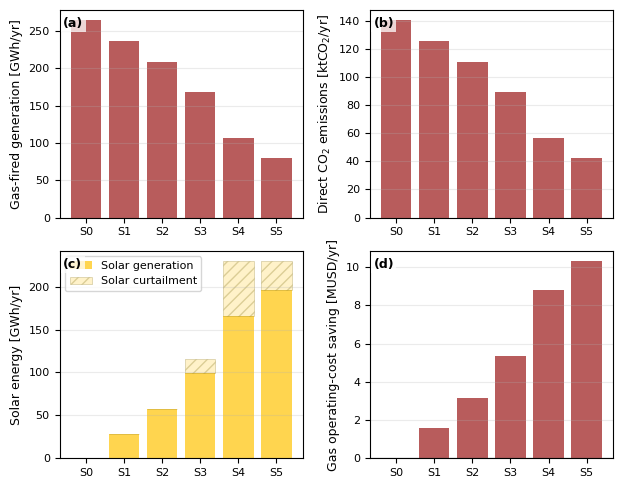

,pathway_stage,pv_homes,bess_homes,pv_penetration_pct,bess_share_of_pv_pct,pv_mw,bess_mw,bess_mwh
0,S0,0,0,0.0,0.0,0.0,0.0,0.0
1,S1,5000,0,10.1,0.0,25.0,0.0,0.0
2,S2,10000,1000,20.2,10.0,50.0,5.0,10.0
3,S3,20000,5000,40.3,25.0,100.0,25.0,50.0
4,S4,40000,20000,80.7,50.0,200.0,100.0,200.0
5,S5,40000,40000,80.7,100.0,200.0,200.0,400.0


In [8]:
# ── 6. Main adoption-pathway figure ──
plot_df = summary[summary["code"].astype(str).isin(PATHWAY_CODES)].copy()
plot_df["_order"] = plot_df["code"].astype(str).map(
    {code: i for i, code in enumerate(PATHWAY_CODES)}
)
plot_df = plot_df.sort_values("_order")

labels = plot_df["pathway_stage"].astype(str).tolist()
x = np.arange(len(plot_df))

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_PAPER_2X2)

# (a) Gas-fired generation
axes[0, 0].bar(
    x,
    plot_df["thermal_generation_mwh"] / 1e3,
    color=TECH_COLORS["gas"],
)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(labels)
finish_axis(axes[0, 0], ylabel="Gas-fired generation [GWh/yr]")
panel_label(axes[0, 0], "(a)")

# (b) Direct CO2 emissions
axes[0, 1].bar(
    x,
    plot_df["co2_tons"] / 1e3,
    color=TECH_COLORS["gas"],
)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(labels)
finish_axis(axes[0, 1], ylabel="Direct CO$_2$ emissions [ktCO$_2$/yr]")
panel_label(axes[0, 1], "(b)")

# (c) Solar generation and curtailment
solar_gen = plot_df["solar_generation_mwh"] / 1e3
solar_curt = plot_df["solar_curtailment_mwh"] / 1e3

axes[1, 0].bar(
    x,
    solar_gen,
    color=TECH_COLORS["solar"],
    label="Solar generation",
)
axes[1, 0].bar(
    x,
    solar_curt,
    bottom=solar_gen,
    color=TECH_COLORS["solar"],
    alpha=0.30,
    hatch="///",
    edgecolor="#8a7a20",
    linewidth=0.6,
    label="Solar curtailment",
)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(labels)
finish_axis(axes[1, 0], ylabel="Solar energy [GWh/yr]")
axes[1, 0].legend(frameon=True, loc="upper left")
panel_label(axes[1, 0], "(c)")

# (d) Avoided gas operating cost
axes[1, 1].bar(
    x,
    plot_df["thermal_cost_saving_usd"] / 1e6,
    color=TECH_COLORS["gas"],
)
axes[1, 1].axhline(0, linewidth=0.8, color="0.25")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(labels)
finish_axis(axes[1, 1], ylabel="Gas operating-cost saving [MUSD/yr]")
panel_label(axes[1, 1], "(d)")

fig.tight_layout()
save_paper_figure(fig, "cinvie_2025_adoption_pathway_system_impacts.png")
plt.show()

# Compact scenario key for manuscript/figure caption
scenario_key = plot_df[
    [
        "pathway_stage",
        "pv_homes",
        "bess_homes",
        "pv_penetration_pct",
        "bess_share_of_pv_pct",
        "pv_mw",
        "bess_mw",
        "bess_mwh",
    ]
].copy()

display(scenario_key.round(1))
scenario_key.to_csv(
    TABLE_DIR / "cinvie_2025_pathway_scenario_key.csv",
    index=False,
)


,pv_homes,bess_homes,pv_mw,bess_mw,bess_mwh,gas_generation_pv_gwh,gas_generation_pvbess_gwh,additional_gas_reduction_from_bess_gwh,co2_pv_kt,co2_pvbess_kt,additional_co2_reduction_from_bess_kt,curtailment_pv_pct,curtailment_pvbess_pct,curtailment_reduction_pp,bess_charge_gwh,bess_discharge_gwh
0,10000,1000,50.0,5.0,10.0,208.812,208.218,0.594,111.000,110.684,0.316,1.346,0.602,0.744,0.682,0.606
1,20000,5000,100.0,25.0,50.0,179.224,168.730,10.494,95.272,89.694,5.578,23.131,13.464,9.667,11.871,10.528
2,40000,20000,200.0,100.0,200.0,158.731,106.691,52.041,84.378,56.715,27.664,52.022,27.805,24.217,57.663,52.041
3,40000,40000,200.0,200.0,400.0,158.731,79.327,79.404,84.378,42.168,42.210,52.022,15.059,36.963,87.983,79.404


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_incremental_bess_value.png


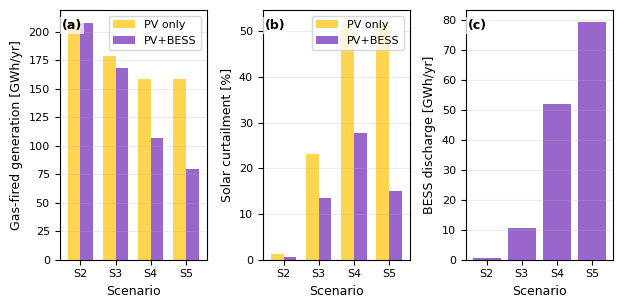

In [9]:
# ── 7. Incremental value of BESS at equal PV penetration ──
BESS_COMPARISONS = [
    ("CF_PV10000", "S2_PV10000_BESS1000", 10_000, 1_000),
    ("CF_PV20000", "S3_PV20000_BESS5000", 20_000, 5_000),
    ("CF_PV40000", "S4_PV40000_BESS20000", 40_000, 20_000),
    ("CF_PV40000", "S5_PV40000_BESS40000", 40_000, 40_000),
]

pair_rows = []

for pv_code, pvb_code, pv_homes, bess_homes in BESS_COMPARISONS:
    pv = summary[summary["code"].astype(str).eq(pv_code)].iloc[0]
    pvb = summary[summary["code"].astype(str).eq(pvb_code)].iloc[0]

    pair_rows.append({
        "pv_homes": pv_homes,
        "bess_homes": bess_homes,
        "pv_mw": pv["pv_mw"],
        "bess_mw": pvb["bess_mw"],
        "bess_mwh": pvb["bess_mwh"],
        "gas_generation_pv_gwh": pv["thermal_generation_mwh"] / 1e3,
        "gas_generation_pvbess_gwh": pvb["thermal_generation_mwh"] / 1e3,
        "additional_gas_reduction_from_bess_gwh": (
            pv["thermal_generation_mwh"] - pvb["thermal_generation_mwh"]
        ) / 1e3,
        "co2_pv_kt": pv["co2_tons"] / 1e3,
        "co2_pvbess_kt": pvb["co2_tons"] / 1e3,
        "additional_co2_reduction_from_bess_kt": (
            pv["co2_tons"] - pvb["co2_tons"]
        ) / 1e3,
        "curtailment_pv_pct": pv["solar_curtailment_pct"],
        "curtailment_pvbess_pct": pvb["solar_curtailment_pct"],
        "curtailment_reduction_pp": (
            pv["solar_curtailment_pct"] - pvb["solar_curtailment_pct"]
        ),
        "bess_charge_gwh": pvb["bess_charge_mwh"] / 1e3,
        "bess_discharge_gwh": pvb["bess_discharge_mwh"] / 1e3,
    })

pair_df = pd.DataFrame(pair_rows)
display(pair_df.round(3))
pair_df.to_csv(
    TABLE_DIR / "cinvie_2025_incremental_bess_value.csv",
    index=False,
)

x = np.arange(len(pair_df))
width = 0.36

tick_labels = ["S2", "S3", "S4", "S5"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(WORD_DOUBLE_COL_IN, 3.15),
    sharex=True,
)

# (a) Gas generation
axes[0].bar(
    x - width/2,
    pair_df["gas_generation_pv_gwh"],
    width,
    color=TECH_COLORS["solar"],
    label="PV only",
)
axes[0].bar(
    x + width/2,
    pair_df["gas_generation_pvbess_gwh"],
    width,
    color=TECH_COLORS["bess"],
    label="PV+BESS",
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tick_labels)
finish_axis(
    axes[0],
    xlabel="Scenario",
    ylabel="Gas-fired generation [GWh/yr]",
)
axes[0].legend(frameon=True)
panel_label(axes[0], "(a)")

# (b) Curtailment
axes[1].bar(
    x - width/2,
    pair_df["curtailment_pv_pct"],
    width,
    color=TECH_COLORS["solar"],
    label="PV only",
)
axes[1].bar(
    x + width/2,
    pair_df["curtailment_pvbess_pct"],
    width,
    color=TECH_COLORS["bess"],
    label="PV+BESS",
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(tick_labels)
finish_axis(
    axes[1],
    xlabel="Scenario",
    ylabel="Solar curtailment [%]",
)
axes[1].legend(frameon=True)
panel_label(axes[1], "(b)")

# (c) Storage utilisation
axes[2].bar(
    x,
    pair_df["bess_discharge_gwh"],
    color=TECH_COLORS["bess"],
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(tick_labels)
finish_axis(
    axes[2],
    xlabel="Scenario",
    ylabel="BESS discharge [GWh/yr]",
)
panel_label(axes[2], "(c)")

fig.tight_layout()
save_paper_figure(
    fig,
    "cinvie_2025_incremental_bess_value.png",
)
plt.show()


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_dispatch_winter_summer.png


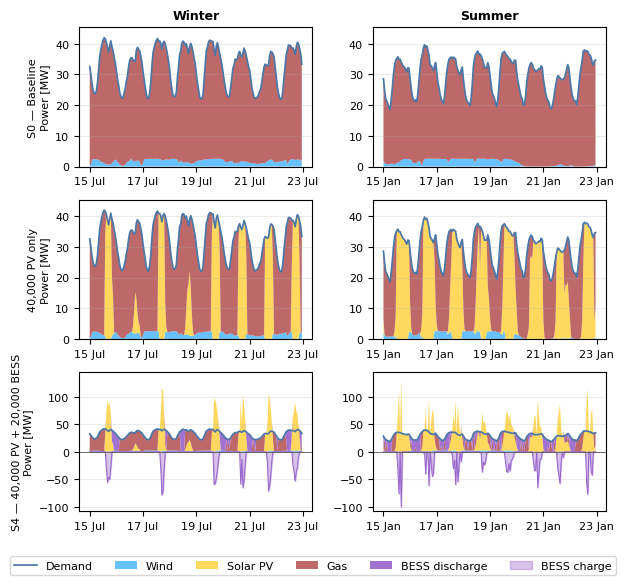

In [10]:
# ── 8. Seasonal dispatch: winter and summer in one figure ──
FOCUS_SCENARIOS = [
    "BASE",
    "CF_PV40000",
    "S4_PV40000_BESS20000",
]

FOCUS_ROW_LABELS = {
    "BASE": "S0 — Baseline",
    "CF_PV40000": "40,000 PV only",
    "S4_PV40000_BESS20000": "S4 — 40,000 PV + 20,000 BESS",
}

WINDOWS = {
    "Winter": (f"{MODEL_YEAR}-07-15", f"{MODEL_YEAR}-07-22"),
    "Summer": (f"{MODEL_YEAR}-01-15", f"{MODEL_YEAR}-01-22"),
}


def load_hourly(code: str) -> pd.DataFrame:
    path = HOURLY_DIR / f"{code}_2025.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing hourly output: {path}")
    return pd.read_csv(path, parse_dates=["timestamp"]).set_index("timestamp")


# Preload each row/season to calculate consistent y-limits across columns.
dispatch_data = {}
row_limits = {}

for code in FOCUS_SCENARIOS:
    dispatch_data[code] = {}
    row_positive_max = 0.0
    row_negative_min = 0.0

    for season, (start, end) in WINDOWS.items():
        h = load_hourly(code).loc[start:end].copy()
        dispatch_data[code][season] = h

        positive_stack = (
            h["wind_mw"].clip(lower=0)
            + h["solar_mw"].clip(lower=0)
            + h["thermal_mw"].clip(lower=0)
            + h["bess_discharge_mw"].clip(lower=0)
        )
        row_positive_max = max(
            row_positive_max,
            float(positive_stack.max()),
            float(h["demand_mw"].max()),
        )
        row_negative_min = min(
            row_negative_min,
            float((-h["bess_charge_mw"].clip(lower=0)).min()),
        )

    upper = max(5.0, row_positive_max * 1.08)
    lower = row_negative_min * 1.08 if row_negative_min < -1e-6 else 0.0
    row_limits[code] = (lower, upper)


fig, axes = plt.subplots(
    nrows=len(FOCUS_SCENARIOS),
    ncols=len(WINDOWS),
    figsize=(WORD_DOUBLE_COL_IN, 6.0),
    sharex=False,
)

season_names = list(WINDOWS.keys())

for row_i, code in enumerate(FOCUS_SCENARIOS):
    for col_i, season in enumerate(season_names):
        ax = axes[row_i, col_i]
        h = dispatch_data[code][season]

        ax.stackplot(
            h.index,
            h["wind_mw"].clip(lower=0),
            h["solar_mw"].clip(lower=0),
            h["thermal_mw"].clip(lower=0),
            h["bess_discharge_mw"].clip(lower=0),
            labels=["Wind", "Solar PV", "Gas", "BESS discharge"],
            colors=[
                TECH_COLORS["wind"],
                TECH_COLORS["solar"],
                TECH_COLORS["gas"],
                TECH_COLORS["bess"],
            ],
            alpha=0.92,
        )

        charge = h["bess_charge_mw"].clip(lower=0)
        if charge.max() > 1e-6:
            ax.fill_between(
                h.index,
                0,
                -charge,
                color=TECH_COLORS["bess"],
                alpha=0.38,
                label="BESS charge",
            )
            ax.plot(
                h.index,
                -charge,
                color=TECH_COLORS["bess"],
                linewidth=0.7,
            )

        ax.plot(
            h.index,
            h["demand_mw"],
            color=DEMAND_COLOR,
            linewidth=1.25,
            label="Demand",
            zorder=10,
        )

        ax.axhline(0, linewidth=0.6, color="0.35")
        ax.set_ylim(*row_limits[code])
        ax.grid(True, axis="y", alpha=GRID_ALPHA)
        ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)

        # Compact date ticks for the two-column layout.
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

        if row_i == 0:
            ax.set_title(season, fontsize=FONT_SIZE_LABEL, fontweight="bold")

        if col_i == 0:
            ax.set_ylabel(
                f"{FOCUS_ROW_LABELS[code]}\nPower [MW]",
                fontsize=FONT_SIZE_SMALL,
            )

# One common legend for the whole figure.
handles, labels = [], []
for ax in axes.flat:
    h_i, l_i = ax.get_legend_handles_labels()
    for handle, label in zip(h_i, l_i):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

preferred_order = [
    "Demand",
    "Wind",
    "Solar PV",
    "Gas",
    "BESS discharge",
    "BESS charge",
]
ordered = [
    (handles[labels.index(label)], label)
    for label in preferred_order
    if label in labels
]

fig.legend(
    [h for h, _ in ordered],
    [l for _, l in ordered],
    loc="lower center",
    ncol=6,
    frameon=True,
    bbox_to_anchor=(0.5, -0.005),
)

#fig.suptitle(
#    "Seasonal dispatch — Punta Arenas 2025",
#    fontsize=FONT_SIZE_BASE + 1,
#)
fig.tight_layout(rect=[0, 0.055, 1, 0.97])

save_paper_figure(
    fig,
    "cinvie_2025_dispatch_winter_summer.png",
)
plt.show()


In [11]:
# ── 9. Optional household-economic layer ──
# Optional simple-payback template — intentionally left inactive by default.
RUN_HOUSEHOLD_ECONOMICS = False

if RUN_HOUSEHOLD_ECONOMICS:
    # Replace with referenced Chile/Punta Arenas retail values.
    retail_pv_cost_clp = np.nan
    retail_pvbess_cost_clp = np.nan
    annual_household_saving_pv_clp = np.nan
    annual_household_saving_pvbess_clp = np.nan

    economics = pd.DataFrame({
        "system": ["PV", "PV+BESS"],
        "investment_clp": [retail_pv_cost_clp, retail_pvbess_cost_clp],
        "annual_saving_clp": [
            annual_household_saving_pv_clp,
            annual_household_saving_pvbess_clp,
        ],
    })
    economics["simple_payback_years"] = (
        economics["investment_clp"] / economics["annual_saving_clp"]
    )
    display(economics)
else:
    print(
        "Household economics disabled. "
        "System-level CINVIE results are available in scenario_summary."
    )


Household economics disabled. System-level CINVIE results are available in scenario_summary.


In [12]:
# ── v2 Household BTM controls ─────────────────────────────────────────────────
# Input is compatible with the SAME CINVIE output directories and case-year.
BTM_DEMAND_CSV = Path(CASE_FOLDER) / "demand_residential_hourly_2025.csv"
BTM_USE_SYSTEM_LOAD_PROXY_IF_MISSING = True
BTM_MONTHLY_KWH_PER_HOME = 178.0   # ILLUSTRATIVE ONLY, not measured in this notebook

# Prefer exported available PV; accept S1 dispatched proxy only if curtailment <= threshold.
BTM_ALLOW_NEAR_UNCURTAILED_S1_PROXY = True
BTM_MAX_S1_CURTAILMENT_PCT_FOR_PROXY = 0.5

# Household technology (inherits 5 kW / 5 kW / 10 kWh from original notebook)
BTM_CHARGE_EFFICIENCY = 0.95     # assumption, charging stage
BTM_DISCHARGE_EFFICIENCY = 0.95  # assumption, discharge stage
BTM_INITIAL_SOC_FRACTION = 0.50

# Economic parameters: PLACEHOLDERS for sensitivity only; replace with referenced prices.
BTM_RETAIL_CLP_KWH = 180.0        # ILLUSTRATIVE; not a regulated EDELMAG tariff
BTM_EXPORT_CREDIT_CLP_KWH = 75.0  # ILLUSTRATIVE; not a verified injection rate
BTM_PV_CAPEX_CLP = 3_500_000.0   # ILLUSTRATIVE, PV-only
BTM_PVBESS_CAPEX_CLP = 7_000_000.0  # ILLUSTRATIVE; within 6–8 M CLP study range
BTM_PV_ANNUAL_OM_CLP = 0.0        # omitted/zero, not validated
BTM_PVBESS_ANNUAL_OM_CLP = 0.0    # omitted/zero, not validated

# Equivalent annual cost (EAC) sensitivity, NOT an observed financing offer.
BTM_PROJECT_LIFETIME_YEARS = 20   # Illustrative common accounting horizon
BTM_REAL_DISCOUNT_RATE = 0.06     # Illustrative real discount rate (6%)
# No BESS replacement/aging/salvage is included: optimistic for PV+BESS.
# For simple undiscouted CAPEX/year, set BTM_REAL_DISCOUNT_RATE = 0.
assert BTM_PROJECT_LIFETIME_YEARS > 0 and BTM_REAL_DISCOUNT_RATE >= 0

# Resilience ASSUMES islandable inverter, switching/protection and adequate system design.
BTM_BESS_BACKUP_CAPABLE = True
BTM_PV_ONLY_BACKUP_CAPABLE = False  # most ordinary grid-following PV shuts down in outages
BTM_ESSENTIAL_LOAD_SHARE = 0.40     # sensitivity for priority loads; not a measured share
BTM_OUTAGE_DURATIONS_H = (6, 12, 24, 48, 72)
BTM_OUTAGE_START_STEP_H = 6         # 4 starts/day, every season, no probability interpretation

# Optional when a household load CSV is available: use exact kW values, no rescaling.
BTM_SCENARIO_FOR_SYSTEM_COUPLING = "S4_PV40000_BESS20000"
BTM_FIGURE_4_WINDOW_DAYS = 3

assert 0 < BTM_CHARGE_EFFICIENCY <= 1
assert 0 < BTM_DISCHARGE_EFFICIENCY <= 1
assert 0 < BTM_ESSENTIAL_LOAD_SHARE <= 1
assert 0 <= BTM_INITIAL_SOC_FRACTION <= 1
assert BTM_EXPORT_CREDIT_CLP_KWH >= 0 and BTM_RETAIL_CLP_KWH >= 0
assert BTM_PVBESS_CAPEX_CLP >= BTM_PV_CAPEX_CLP >= 0

print("v2 inputs:", CASE_FOLDER, "/", HOURLY_DIR)
print("Residential demand:", BTM_DEMAND_CSV if BTM_DEMAND_CSV.exists() else "system-load SHAPE proxy")
print("Economics: illustrative assumptions; NOT actual Punta Arenas household bills.")

v2 inputs: input_punta_arenas / output\output_punta_arenas_cinvie\hourly
Residential demand: system-load SHAPE proxy
Economics: illustrative assumptions; NOT actual Punta Arenas household bills.


In [13]:
# ── Hourly PV and household load inputs ──
def btm_require_hourly_index(df: pd.DataFrame, name: str) -> pd.DataFrame:
    d = df.copy()
    if not isinstance(d.index, pd.DatetimeIndex):
        raise TypeError(f"{name} must have an hourly DatetimeIndex.")
    if d.index.has_duplicates or not d.index.is_monotonic_increasing:
        raise ValueError(f"{name} has duplicated/non-increasing timestamps.")
    if d.index.tz is not None:
        raise ValueError(f"{name} uses timezone-aware timestamps; align all source series first.")
    if len(d) < 2 or not (d.index.to_series().diff().iloc[1:] == pd.Timedelta(hours=1)).all():
        raise ValueError(f"{name} requires uninterrupted hourly timestamps (1 h intervals).")
    return d


def btm_get_pv_and_household_load():
    s1_code = "S1_PV5000"
    s1 = btm_require_hourly_index(load_hourly(s1_code), "S1 saved hourly")
    if s1.index.year.nunique() != 1 or s1.index.year[0] != MODEL_YEAR:
        raise ValueError(f"S1 timestamps must be from {MODEL_YEAR}.")
    if not ((s1.index.month == 1).any() and (s1.index.month == 12).any()):
        raise ValueError("S1 hourly data should cover the full calendar year.")

    if "pv_available_mw" in s1.columns:
        solar_total = pd.to_numeric(s1["pv_available_mw"], errors="raise")
        solar_origin = "PyPSA solar availability (S1 CINVIE PV p_max_pu × p_nom)"
    else:
        if not BTM_ALLOW_NEAR_UNCURTAILED_S1_PROXY:
            raise FileNotFoundError("S1 hourly lacks pv_available_mw. Regenerate S1 with v2 exporter.")
        hit = summary.loc[summary["code"].astype(str).eq(s1_code)]
        if hit.empty:
            raise ValueError("S1 scenario summary not found.")
        pct = float(hit.iloc[0]["solar_curtailment_pct"])
        if pct > BTM_MAX_S1_CURTAILMENT_PCT_FOR_PROXY:
            raise RuntimeError(
                f"S1 curtailed {pct:.2f}% of solar; dispatched energy is NOT resource availability. "
                "Regenerate S1 hourly with pv_available_mw using v2."
            )
        # Exclude any preexisting solar by subtracting the BASE series at each timestamp.
        base = btm_require_hourly_index(load_hourly("BASE"), "BASE saved hourly")
        if not s1.index.equals(base.index):
            raise ValueError("BASE and S1 timestamps differ; do not align by position.")
        solar_total = (s1["solar_mw"] - base["solar_mw"]).clip(lower=0)
        solar_origin = f"S1 − BASE dispatched solar (proxy; S1 curtailment {pct:.3f}%)"
        print("WARNING: Using S1 dispatched PV, not available PV. Approximation due to missing availability export.")

    pv_kw = solar_total.to_numpy(dtype=float) * 1_000.0 / 5_000.0
    if not np.all(np.isfinite(pv_kw)) or (pv_kw < -1e-8).any():
        raise ValueError("Invalid solar generation values.")
    if pv_kw.max() > PV_KW_PER_HOME * 1.05:
        raise ValueError("PV exceeds household nameplate capacity; inspect source columns.")

    base = btm_require_hourly_index(load_hourly("BASE"), "BASE saved hourly")
    if not s1.index.equals(base.index):
        raise ValueError("BASE and S1 timestamps mismatch.")

    if BTM_DEMAND_CSV.exists():
        raw = pd.read_csv(BTM_DEMAND_CSV, parse_dates=["timestamp"])
        if "timestamp" not in raw.columns:
            raise ValueError("Household CSV needs 'timestamp' column.")
        raw = raw.set_index("timestamp")
        raw = btm_require_hourly_index(raw, "household measured load")
        if not raw.index.equals(s1.index):
            raise ValueError("Household CSV timestamps do not match the S1 2025 timestamps.")
        col = next((x for x in ("load_kw", "demand_kw", "load_kwh", "demand_kwh") if x in raw.columns), None)
        if col is None:
            raise ValueError("Household CSV needs load_kw / demand_kw / load_kwh / demand_kwh.")
        load_kw = pd.to_numeric(raw[col], errors="raise").to_numpy(dtype=float)
        demand_origin = f"user CSV {BTM_DEMAND_CSV} ({col})"
    else:
        if not BTM_USE_SYSTEM_LOAD_PROXY_IF_MISSING:
            raise FileNotFoundError(f"Household demand not found: {BTM_DEMAND_CSV}")
        system_shape = pd.to_numeric(base["demand_mw"], errors="raise").to_numpy(dtype=float)
        if system_shape.min() < 0 or system_shape.sum() <= 0:
            raise ValueError("Invalid BASE demand; cannot construct a normalized load shape.")
        annual_household_kwh = BTM_MONTHLY_KWH_PER_HOME * 12
        load_kw = annual_household_kwh * system_shape / system_shape.sum()
        demand_origin = (
            f"ASSUMED {BTM_MONTHLY_KWH_PER_HOME:g} kWh/month; "
            "shape scaled from actual 2025 system demand, NOT residential metering"
        )
        print("WARNING: residential hourly load is a SYSTEM-LOAD SHAPE PROXY, NOT metered household data.")

    if not np.all(np.isfinite(load_kw)) or (load_kw < 0).any():
        raise ValueError("Household load must be nonnegative and finite.")

    household = pd.DataFrame({"load_kw":load_kw,"pv_available_kw":pv_kw}, index=s1.index)
    household.index.name = "timestamp"
    print("Solar profile:", solar_origin)
    print("Demand profile:", demand_origin)
    print(f"PV generation: {household.pv_available_kw.sum():,.0f} kWh/year per 5 kW home")
    print(f"Household load: {household.load_kw.sum():,.0f} kWh/year per home")
    return household, {"solar_origin":solar_origin,"demand_origin":demand_origin}

btm_household_input, btm_input_provenance = btm_get_pv_and_household_load()
display(btm_household_input.head())

Solar profile: S1 − BASE dispatched solar (proxy; S1 curtailment 0.000%)
Demand profile: ASSUMED 178 kWh/month; shape scaled from actual 2025 system demand, NOT residential metering
PV generation: 5,756 kWh/year per 5 kW home
Household load: 2,136 kWh/year per home


,load_kw,pv_available_kw
timestamp,,
2025-01-01 00:00:00,0.220580,0.202549
2025-01-01 01:00:00,0.214663,0.042152
2025-01-01 02:00:00,0.201122,0.000000
2025-01-01 03:00:00,0.183611,0.000000
2025-01-01 04:00:00,0.168824,0.000000


In [14]:
# ── Behind-the-meter dispatch and electricity bills ──
def btm_dispatch_household(
    data: pd.DataFrame, *, bess: bool, initial_soc_fraction: float = 0.5,
    charge_efficiency: float = BTM_CHARGE_EFFICIENCY,
    discharge_efficiency: float = BTM_DISCHARGE_EFFICIENCY,
) -> pd.DataFrame:
    """One home, hourly energy balance. Units: kWh/h == kW for a 1-h step."""
    data = btm_require_hourly_index(data, "BTM household")
    load = data["load_kw"].to_numpy(dtype=float)
    pv = data["pv_available_kw"].to_numpy(dtype=float)
    if not (np.isfinite(load).all() and np.isfinite(pv).all()) or min(load.min(),pv.min()) < 0:
        raise ValueError("BTM load and solar must be finite/nonnegative.")

    capacity = BESS_KWH_PER_HOME if bess else 0.0
    power = BESS_KW_PER_HOME if bess else 0.0
    n = len(load)

    def one_pass(start_soc, return_arrays):
        soc = float(start_soc)
        arr = np.zeros((n,8), dtype=float) if return_arrays else None
        for t in range(n):
            direct = min(load[t], pv[t])
            residual = max(0.0, load[t] - direct)
            surplus = max(0.0, pv[t] - direct)
            soc_before = soc
            ch = 0.0
            dis = 0.0
            if bess and surplus > 0:
                ch = min(surplus, power, (capacity-soc)/charge_efficiency)
                soc += ch * charge_efficiency
            elif bess and residual > 0:
                dis = min(residual, power, soc * discharge_efficiency)
                soc -= dis / discharge_efficiency
            soc = float(np.clip(soc,0,capacity))
            imported = max(0.0, residual-dis)
            exported = max(0.0, surplus-ch)
            if return_arrays:
                arr[t,:] = [direct,ch,dis,imported,exported,soc_before,soc,load[t]]
        return soc, arr

    # Warm-up: set annual-state boundary from a preceding identical weather year.
    end_soc, _ = one_pass(capacity*initial_soc_fraction, False)
    _, result = one_pass(end_soc, True)
    cols = ["pv_direct_kw","bess_charge_kw","bess_discharge_kw",
            "grid_import_kw","grid_export_kw","soc_start_kwh","soc_end_kwh","load_copy_kw"]
    out = pd.DataFrame(result, index=data.index, columns=cols)
    out["pv_available_kw"] = pv
    out["load_kw"] = load
    out["net_grid_kw"] = out.grid_import_kw - out.grid_export_kw
    assert np.allclose(out.pv_direct_kw+out.bess_discharge_kw+out.grid_import_kw,load,atol=1e-7)
    assert np.allclose(out.pv_direct_kw+out.bess_charge_kw+out.grid_export_kw,pv,atol=1e-7)
    assert (out.soc_end_kwh >= -1e-8).all() and (out.soc_end_kwh <= capacity+1e-8).all()
    return out.drop(columns="load_copy_kw")


def btm_bill_and_economics(ops: pd.DataFrame, *, capex_clp: float, annual_om_clp: float):
    """Simple monthly electricity-charge / exported-energy credit calculation."""
    retail = float(BTM_RETAIL_CLP_KWH)
    export = float(BTM_EXPORT_CREDIT_CLP_KWH)
    import_cost = ops.grid_import_kw.resample("MS").sum()*retail
    raw_export_credit = ops.grid_export_kw.resample("MS").sum()*export
    credit_used = np.minimum(import_cost.to_numpy(),raw_export_credit.to_numpy())
    annual_bill = float(import_cost.sum()-credit_used.sum())
    baseline_bill = float(ops.load_kw.sum()*retail)
    saving = baseline_bill - annual_bill - annual_om_clp
    return {
        "annual_household_load_kwh":float(ops.load_kw.sum()),
        "annual_pv_available_kwh":float(ops.pv_available_kw.sum()),
        "annual_pv_direct_kwh":float(ops.pv_direct_kw.sum()),
        "annual_bess_discharge_kwh":float(ops.bess_discharge_kw.sum()),
        "annual_grid_import_kwh":float(ops.grid_import_kw.sum()),
        "annual_grid_export_kwh":float(ops.grid_export_kw.sum()),
        "pv_self_consumption_pct":float(100*(ops.pv_direct_kw.sum()+ops.bess_charge_kw.sum()) / max(ops.pv_available_kw.sum(),1e-9)),
        "baseline_energy_bill_clp_yr":baseline_bill,
        "energy_bill_clp_yr":annual_bill,
        "export_credit_used_clp_yr":float(credit_used.sum()),
        "export_credit_not_used_clp_yr":float(raw_export_credit.sum()-credit_used.sum()),
        "gross_annual_bill_saving_clp":baseline_bill-annual_bill,
        "annual_om_clp":annual_om_clp,
        "net_annual_saving_clp":saving,
        "investment_clp":capex_clp,
        "simple_payback_years":capex_clp/saving if saving>0 else np.nan,
    }

btm_pv = btm_dispatch_household(btm_household_input,bess=False,initial_soc_fraction=BTM_INITIAL_SOC_FRACTION)
btm_pvbess = btm_dispatch_household(btm_household_input,bess=True,initial_soc_fraction=BTM_INITIAL_SOC_FRACTION)

btm_economic_rows = []
for system,ops,capex,om in [
    ("PV only",btm_pv,BTM_PV_CAPEX_CLP,BTM_PV_ANNUAL_OM_CLP),
    ("PV+BESS",btm_pvbess,BTM_PVBESS_CAPEX_CLP,BTM_PVBESS_ANNUAL_OM_CLP),
]:
    btm_economic_rows.append({"system":system,**btm_bill_and_economics(ops,capex_clp=capex,annual_om_clp=om)})
btm_economics = pd.DataFrame(btm_economic_rows).set_index("system")
btm_economics["assumption_note"] = "ILLUSTRATIVE tariffs/CAPEX; check local prices and net-billing"

def btm_capital_recovery_factor(rate: float, years: int) -> float:
    """Real annuity factor, with a zero-interest straight-line limiting case."""
    if years <= 0 or rate < 0:
        raise ValueError("years must be positive and the real discount rate nonnegative")
    return 1.0 / years if rate == 0 else rate / (1 - (1 + rate)**(-years))

BTM_CAPITAL_RECOVERY_FACTOR = btm_capital_recovery_factor(
    BTM_REAL_DISCOUNT_RATE, BTM_PROJECT_LIFETIME_YEARS)
btm_economics["annualised_capex_clp_yr"] = (
    btm_economics["investment_clp"] * BTM_CAPITAL_RECOVERY_FACTOR)
btm_economics["annual_equivalent_total_cost_clp_yr"] = (
    btm_economics["energy_bill_clp_yr"]
    + btm_economics["annualised_capex_clp_yr"]
    + btm_economics["annual_om_clp"])
print(f"Annualisation: {BTM_PROJECT_LIFETIME_YEARS} years, "
      f"{BTM_REAL_DISCOUNT_RATE:.1%} real; capital recovery factor "
      f"{BTM_CAPITAL_RECOVERY_FACTOR:.5f}")

bess_extra_saving = btm_economics.loc["PV+BESS","net_annual_saving_clp"]-btm_economics.loc["PV only","net_annual_saving_clp"]
bess_extra_capex = BTM_PVBESS_CAPEX_CLP-BTM_PV_CAPEX_CLP
btm_incremental_bess_payback = bess_extra_capex/bess_extra_saving if bess_extra_saving>0 else np.nan
print("Incremental BESS simple payback vs PV-only:", round(btm_incremental_bess_payback,1) if np.isfinite(btm_incremental_bess_payback) else "No positive incremental bill saving")
display(btm_economics.round(1))

btm_economics.to_csv(TABLE_DIR/"cinvie_v2_household_economic_sensitivity.csv")
btm_pv.to_csv(HOURLY_DIR/"cinvie_v2_household_PV_only.csv")
btm_pvbess.to_csv(HOURLY_DIR/"cinvie_v2_household_PV_BESS.csv")

Annualisation: 20 years, 6.0% real; capital recovery factor 0.08718
Incremental BESS simple payback vs PV-only: 150.3


,annual_household_load_kwh,annual_pv_available_kwh,annual_pv_direct_kwh,annual_bess_discharge_kwh,annual_grid_import_kwh,annual_grid_export_kwh,pv_self_consumption_pct,baseline_energy_bill_clp_yr,energy_bill_clp_yr,export_credit_used_clp_yr,export_credit_not_used_clp_yr,gross_annual_bill_saving_clp,annual_om_clp,net_annual_saving_clp,investment_clp,simple_payback_years,assumption_note,annualised_capex_clp_yr,annual_equivalent_total_cost_clp_yr
system,,,,,,,,,,,,,,,,,,,
PV only,2136.0,5755.6,1017.4,0.0,1118.6,4738.1,17.7,384480.0,27955.3,173386.4,181972.3,356524.7,0.0,356524.7,3500000.0,9.8,ILLUSTRATIVE tariffs/CAPEX; check local prices...,305145.9,333101.2
PV+BESS,2136.0,5755.6,1017.4,1054.6,64.0,3569.6,38.0,384480.0,4669.9,6847.8,260872.8,379810.1,0.0,379810.1,7000000.0,18.4,ILLUSTRATIVE tariffs/CAPEX; check local prices...,610291.9,614961.8


In [15]:
# ── Blackout tests starting from operational SoC ──
def btm_simulate_islanding(
    ops: pd.DataFrame, start: int, duration_h: int,
    *, demand_fraction: float = 1.0, backup_capable: bool = True, bess_installed: bool = False,
) -> dict:
    """One grid outage; use initial SoC from online schedule, no grid imports or exports."""
    if start < 0 or start+duration_h > len(ops):
        raise IndexError("Outage must fall entirely within modelled period.")
    demand = ops["load_kw"].to_numpy()[start:start+duration_h]*demand_fraction
    available_pv = ops["pv_available_kw"].to_numpy()[start:start+duration_h]
    soc = float(ops["soc_start_kwh"].iat[start]) if backup_capable else 0.0
    bess_on = bool(backup_capable and bess_installed)
    # For a PV-only configuration the caller selects whether a standalone PV inverter exists.
    pv_on = backup_capable
    served_total = 0.0
    needed_total = float(demand.sum())
    first_shortfall = None
    for h in range(duration_h):
        load_t = float(demand[h])
        pv_t = float(available_pv[h]) if pv_on else 0.0
        direct = min(load_t,pv_t)
        deficit = load_t-direct
        surplus = max(0,pv_t-direct)
        discharge = 0.0
        if bess_on:
            if surplus>0:
                charge = min(surplus,BESS_KW_PER_HOME,(BESS_KWH_PER_HOME-soc)/BTM_CHARGE_EFFICIENCY)
                soc += charge*BTM_CHARGE_EFFICIENCY
            elif deficit>0:
                discharge = min(deficit,BESS_KW_PER_HOME,soc*BTM_DISCHARGE_EFFICIENCY)
                soc -= discharge/BTM_DISCHARGE_EFFICIENCY
        served = direct+discharge
        served_total += served
        if load_t-served > 1e-7 and first_shortfall is None:
            first_shortfall = h
    return {
        "outage_start":ops.index[start],
        "outage_duration_h":duration_h,
        "load_requested_kwh":needed_total,
        "load_served_kwh":served_total,
        "load_unserved_kwh":max(0,needed_total-served_total),
        "energy_served_pct":100*served_total/max(needed_total,1e-10),
        "full_service":int(needed_total-served_total<1e-7),
        "first_unserved_hour":float(first_shortfall) if first_shortfall is not None else np.nan,
    }


def btm_islanding_sweep(ops,*,label:str,backup_capable:bool,bess_installed:bool,demand_fraction:float):
    all_rows=[]
    longest=max(BTM_OUTAGE_DURATIONS_H)
    for start in range(0,len(ops)-longest+1,BTM_OUTAGE_START_STEP_H):
        for dur in BTM_OUTAGE_DURATIONS_H:
            row=btm_simulate_islanding(ops,start,dur,demand_fraction=demand_fraction,backup_capable=backup_capable,bess_installed=bess_installed)
            row.update({"system":label,"demand_fraction":demand_fraction})
            all_rows.append(row)
    return pd.DataFrame(all_rows)

btm_outages=pd.concat([
    btm_islanding_sweep(btm_pv,label="PV only",backup_capable=BTM_PV_ONLY_BACKUP_CAPABLE,bess_installed=False,demand_fraction=1.0),
    btm_islanding_sweep(btm_pvbess,label="PV+BESS",backup_capable=BTM_BESS_BACKUP_CAPABLE,bess_installed=True,demand_fraction=1.0),
    btm_islanding_sweep(btm_pvbess,label="PV+BESS essential loads",backup_capable=BTM_BESS_BACKUP_CAPABLE,bess_installed=True,demand_fraction=BTM_ESSENTIAL_LOAD_SHARE),
],ignore_index=True)

btm_resilience=btm_outages.groupby(["system","demand_fraction","outage_duration_h"],as_index=False).agg(
    mean_energy_served_pct=("energy_served_pct","mean"),
    min_energy_served_pct=("energy_served_pct","min"),
    tested_start_times=("full_service","size"),
    fully_covered_starts_pct=("full_service",lambda x:100.0*x.mean()),
    mean_unserved_kwh=("load_unserved_kwh","mean"),
)
btm_outages.to_csv(TABLE_DIR/"cinvie_v2_islanding_all_start_times.csv",index=False)
btm_resilience.to_csv(TABLE_DIR/"cinvie_v2_islanding_summary.csv",index=False)
display(btm_resilience.round(1))


,system,demand_fraction,outage_duration_h,mean_energy_served_pct,min_energy_served_pct,tested_start_times,fully_covered_starts_pct,mean_unserved_kwh
0,PV only,1.0,6,0.0,0.0,1449,0.0,1.5
1,PV only,1.0,12,0.0,0.0,1449,0.0,2.9
2,PV only,1.0,24,0.0,0.0,1449,0.0,5.9
3,PV only,1.0,48,0.0,0.0,1449,0.0,11.7
4,PV only,1.0,72,0.0,0.0,1449,0.0,17.6
5,PV+BESS,1.0,6,97.2,0.0,1449,95.3,0.0
6,PV+BESS,1.0,12,97.2,0.0,1449,94.1,0.1
7,PV+BESS,1.0,24,97.3,11.5,1449,92.1,0.2
8,PV+BESS,1.0,48,97.3,12.7,1449,89.2,0.4
9,PV+BESS,1.0,72,97.3,16.8,1449,86.5,0.5


Household economic components [kCLP/year], illustrative:


,purchase_clp_yr,export_credit_clp_yr,net_bill_clp_yr,annualised_capex_clp_yr,annual_om_clp_yr,annual_equivalent_total_clp_yr
household_type,,,,,,
BAU,384.5,0.0,384.5,0.0,0.0,384.5
PV only,201.3,173.4,28.0,305.1,0.0,333.1
PV+BESS,11.5,6.8,4.7,610.3,0.0,615.0


S0-S5 reference-cohort annual costs [kCLP/home], illustrative:


,mean_net_bill_clp_yr_per_home,mean_annualised_capex_clp_yr_per_home,mean_total_equivalent_annual_cost_clp_per_home
scenario,,,
S0,384.5,0.0,384.5
S1,339.9,38.1,378.1
S2,294.8,83.9,378.7
S3,203.3,190.7,394.0
S4,16.3,457.7,474.0
S5,4.7,610.3,615.0


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_figure4_household_operation_economics_resilience.png
Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_figure4_household_operation_economics_resilience.svg


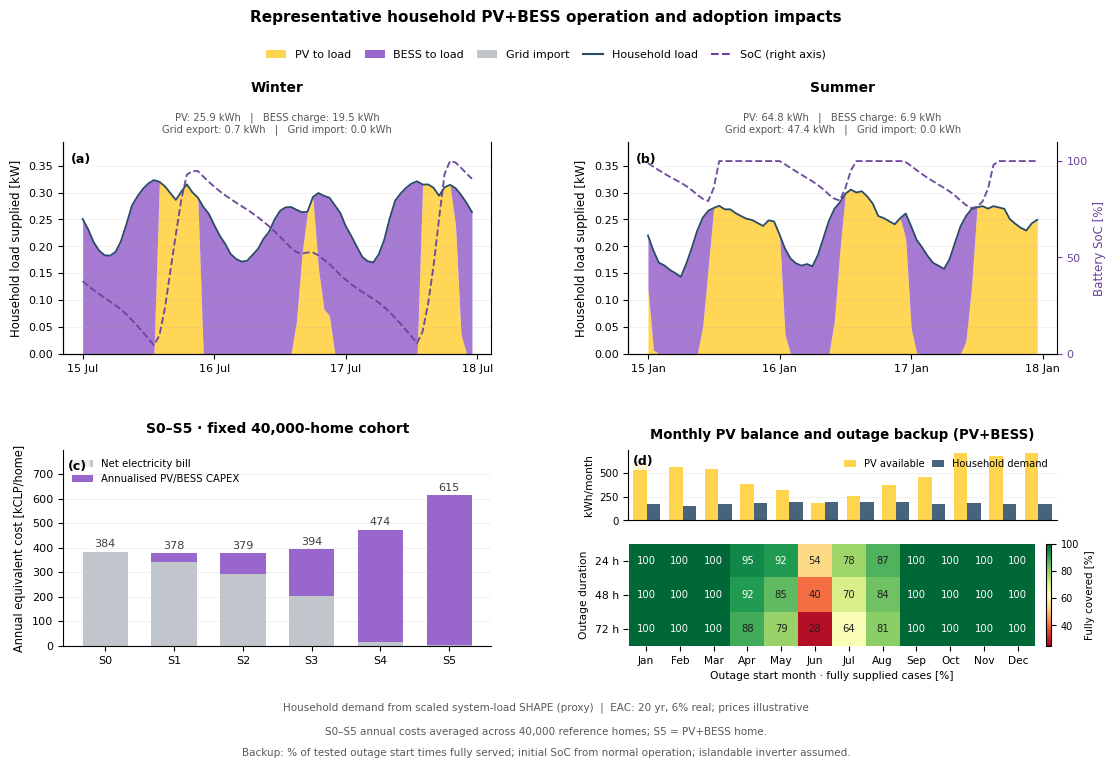

Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_household_bills_BAU_PV_PVBESS.png
Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_2025_household_bills_BAU_PV_PVBESS.svg


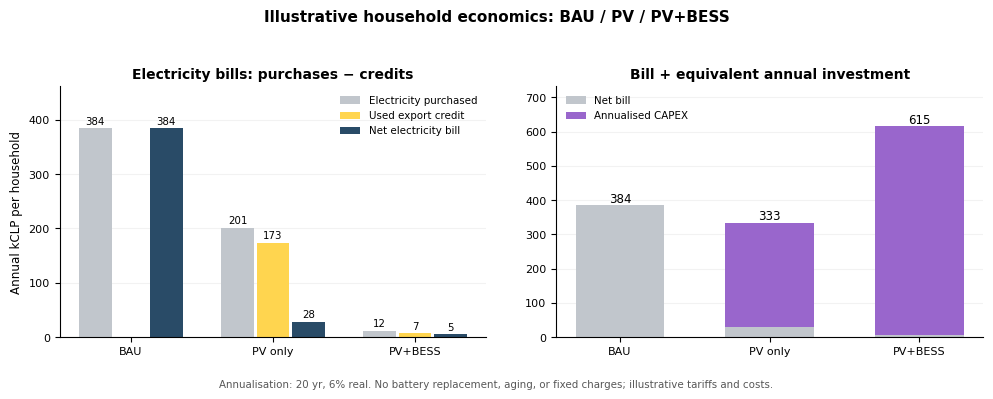

In [16]:
# ── Figure 4: household operation, economics and blackout backup ──
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import calendar

FIG4_COLORS = {
    "pv": TECH_COLORS["solar"],
    "battery": TECH_COLORS["bess"],
    "grid": "#c1c6cc",
    "bau": "#a3aab1",
    "load": "#294b67",
    "soc": "#684399",
    "winter": "#b55f58",
    "summer": "#3980a8",
}

# Detailed household breakdown: purchased electricity minus applied injection credit,
# then plus annualised CAPEX and O&M for a comparable yearly EAC.
btm_bau_purchase = float(btm_household_input.load_kw.sum() * BTM_RETAIL_CLP_KWH)
btm_type_components = {
    "BAU": {"purchase_clp_yr": btm_bau_purchase, "export_credit_clp_yr": 0.0,
            "net_bill_clp_yr": btm_bau_purchase, "annualised_capex_clp_yr": 0.0,
            "annual_om_clp_yr": 0.0},
}
for name in ["PV only", "PV+BESS"]:
    eco = btm_economics.loc[name]
    btm_type_components[name] = {
        "purchase_clp_yr": float(eco["annual_grid_import_kwh"] * BTM_RETAIL_CLP_KWH),
        "export_credit_clp_yr": float(eco["export_credit_used_clp_yr"]),
        "net_bill_clp_yr": float(eco["energy_bill_clp_yr"]),
        "annualised_capex_clp_yr": float(eco["annualised_capex_clp_yr"]),
        "annual_om_clp_yr": float(eco["annual_om_clp"]),
    }
for vals in btm_type_components.values():
    vals["annual_equivalent_total_clp_yr"] = (
        vals["net_bill_clp_yr"] + vals["annualised_capex_clp_yr"]
        + vals["annual_om_clp_yr"])
    assert abs(vals["purchase_clp_yr"]-vals["export_credit_clp_yr"]
               -vals["net_bill_clp_yr"]) < 0.1
btm_type_economic_breakdown = pd.DataFrame.from_dict(btm_type_components,orient="index")
btm_type_economic_breakdown.index.name = "household_type"
btm_type_economic_breakdown.to_csv(TABLE_DIR/"cinvie_v2_household_type_full_annual_costs.csv")
print("Household economic components [kCLP/year], illustrative:")
display((btm_type_economic_breakdown/1000).round(1))

# Calculate per-home economics across a fixed 40,000-home reference cohort.
# S5 equips every home in this cohort with PV+BESS, so its mean must equal
# the standalone PV+BESS result. This is NOT the entire 49,571-home census.
BTM_ECON_REFERENCE_COHORT_HOMES = max(s["pv_homes"] for s in PATHWAY_SCENARIOS)
assert BTM_ECON_REFERENCE_COHORT_HOMES == 40_000

btm_scenario_bill_rows = []
for s in PATHWAY_SCENARIOS:
    n_pvb = int(s["bess_homes"])
    n_pv = int(s["pv_homes"] - s["bess_homes"])
    n_bau = int(BTM_ECON_REFERENCE_COHORT_HOMES - s["pv_homes"])
    if n_bau < 0:
        raise ValueError("PV homes exceed the economic comparison cohort")
    counts = {"BAU": n_bau, "PV only": n_pv, "PV+BESS": n_pvb}
    row = {"scenario": s["pathway_stage"], "code": s["code"],
           "reference_cohort_homes": int(BTM_ECON_REFERENCE_COHORT_HOMES),
           "pv_only_homes": n_pv, "pv_bess_homes": n_pvb, "bau_homes": n_bau}
    for key in btm_type_economic_breakdown.columns:
        row[f"mean_{key}_per_home"] = sum(
            counts[t] * btm_type_components[t][key] / BTM_ECON_REFERENCE_COHORT_HOMES
            for t in counts)
    row["mean_annual_bill_clp_per_home"] = row["mean_net_bill_clp_yr_per_home"]
    row["mean_total_equivalent_annual_cost_clp_per_home"] = row["mean_annual_equivalent_total_clp_yr_per_home"]
    row["mean_bill_saving_from_s0_clp_per_home"] = (
        btm_bau_purchase - row["mean_annual_bill_clp_per_home"])
    btm_scenario_bill_rows.append(row)
btm_scenario_bills = pd.DataFrame(btm_scenario_bill_rows)
# Identical reference population and denominators for Figure 4(c) and the
# standalone household-economics figure. No mixed BAU households in S5.
for scenario_label, household_label in [("S0", "BAU"), ("S5", "PV+BESS")]:
    observed = btm_scenario_bills.loc[
        btm_scenario_bills.scenario.eq(scenario_label),
        "mean_total_equivalent_annual_cost_clp_per_home"
    ].item()
    expected = btm_type_components[household_label]["annual_equivalent_total_clp_yr"]
    np.testing.assert_allclose(observed, expected, rtol=0, atol=0.01)
btm_scenario_bills.to_csv(TABLE_DIR/"cinvie_v2_household_bills_by_adoption_scenario.csv",index=False)
print("S0-S5 reference-cohort annual costs [kCLP/home], illustrative:")
display((btm_scenario_bills[["scenario", "mean_net_bill_clp_yr_per_home",
                           "mean_annualised_capex_clp_yr_per_home",
                           "mean_total_equivalent_annual_cost_clp_per_home"]]
         .set_index("scenario")/1000).round(1))

fig, axs = plt.subplots(2, 2, figsize=(11.5, 8.0),
                        gridspec_kw={"height_ratios": [1.06, 0.98]})
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.08, right=0.944, bottom=0.16, top=0.79,
                    hspace=0.47, wspace=0.32)
fig.suptitle("Representative household PV+BESS operation and adoption impacts",
             fontsize=11, fontweight="bold", y=0.955)
season_windows = [
    ("Winter", f"{MODEL_YEAR}-07-15", f"{MODEL_YEAR}-07-17"),
    ("Summer", f"{MODEL_YEAR}-01-15", f"{MODEL_YEAR}-01-17"),
]
selected_windows = [btm_pvbess.loc[start:end] for _,start,end in season_windows]
common_demand_ylim = max(0.1,*(float(z.load_kw.max()) for z in selected_windows))*1.22

for k,(ax, (season, _, _), h) in enumerate(zip(axs[0], season_windows, selected_windows)):
    x = h.index
    stack1 = h.pv_direct_kw.to_numpy()
    stack2 = stack1 + h.bess_discharge_kw.to_numpy()
    stack3 = stack2 + h.grid_import_kw.to_numpy()
    ax.fill_between(x,0,stack1,color=FIG4_COLORS["pv"],linewidth=0,alpha=0.96)
    ax.fill_between(x,stack1,stack2,color=FIG4_COLORS["battery"],linewidth=0,alpha=0.87)
    ax.fill_between(x,stack2,stack3,color=FIG4_COLORS["grid"],linewidth=0,alpha=0.82)
    ax.plot(x,h.load_kw,color=FIG4_COLORS["load"],lw=1.3,zorder=5)
    ax.text(0.50,1.032,
            f"PV: {h.pv_available_kw.sum():.1f} kWh   |   BESS charge: {h.bess_charge_kw.sum():.1f} kWh\n"
            f"Grid export: {h.grid_export_kw.sum():.1f} kWh   |   Grid import: {h.grid_import_kw.sum():.1f} kWh",
            transform=ax.transAxes,ha="center",va="bottom",fontsize=7.2,color="0.34")
    ax.set_title(season,fontweight="bold",pad=36,fontsize=10)
    ax.set_ylim(0,common_demand_ylim)
    ax.set_ylabel("Household load supplied [kW]",fontsize=8.5)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(axis="y",alpha=0.17)
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(labelsize=8)
    ax_soc=ax.twinx()
    ax_soc.plot(x,100*h.soc_end_kwh/BESS_KWH_PER_HOME,
                color=FIG4_COLORS["soc"],ls="--",lw=1.35,alpha=0.95)
    ax_soc.set_ylim(0,110)
    ax_soc.set_yticks([0,50,100])
    if k==1:
        ax_soc.set_ylabel("Battery SoC [%]",color=FIG4_COLORS["soc"],fontsize=8.5)
        ax_soc.tick_params(axis="y",labelsize=8,colors=FIG4_COLORS["soc"])
    else:
        ax_soc.tick_params(axis="y",right=False,labelright=False)
    ax_soc.spines["top"].set_visible(False)
    panel_label(ax,"(a)" if k==0 else "(b)",x=0.018,y=0.95)

fig.legend(handles=[
    Patch(facecolor=FIG4_COLORS["pv"],label="PV to load"),
    Patch(facecolor=FIG4_COLORS["battery"],label="BESS to load"),
    Patch(facecolor=FIG4_COLORS["grid"],label="Grid import"),
    Line2D([0],[0],color=FIG4_COLORS["load"],lw=1.5,label="Household load"),
    Line2D([0],[0],color=FIG4_COLORS["soc"],lw=1.5,ls="--",label="SoC (right axis)"),
],ncol=5,frameon=False,loc="upper center",bbox_to_anchor=(0.5,0.917),
   fontsize=8,columnspacing=1.2,handlelength=1.8)

# (c): six scenarios. Stacked bars show net bill after USED export credits,
# plus investment annualised at the same configured project horizon/discount rate.
ax=axs[1,0]
xx=np.arange(len(btm_scenario_bills))
bill=btm_scenario_bills["mean_net_bill_clp_yr_per_home"].to_numpy(dtype=float)/1000
capex=btm_scenario_bills["mean_annualised_capex_clp_yr_per_home"].to_numpy(dtype=float)/1000
om=btm_scenario_bills["mean_annual_om_clp_yr_per_home"].to_numpy(dtype=float)/1000
totals=bill+capex+om
ax.bar(xx,bill,width=0.66,color=FIG4_COLORS["grid"],label="Net electricity bill")
ax.bar(xx,capex,bottom=bill,width=0.66,color=FIG4_COLORS["battery"],
       label="Annualised PV/BESS CAPEX")
if np.any(om>0):
    ax.bar(xx,om,bottom=bill+capex,width=0.66,color=FIG4_COLORS["pv"],label="Annual O&M")
for j,total in enumerate(totals):
    ax.text(j,total+max(totals)*0.016,f"{total:.0f}",
            ha="center",va="bottom",fontsize=8,color="0.24")
ax.set_ylim(0,max(totals)*1.30)
ax.set_xticks(xx,btm_scenario_bills["scenario"].tolist())
ax.set_ylabel("Annual equivalent cost [kCLP/home]",fontsize=8.2)
ax.set_title("S0–S5 · fixed 40,000-home cohort",fontweight="bold",fontsize=10,pad=12)
ax.legend(loc="upper left",frameon=False,fontsize=7.3)
ax.grid(axis="y",alpha=0.17)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.tick_params(labelsize=8)
panel_label(ax,"(c)",x=0.012,y=0.95)

# (d): monthly PV availability vs. household load, followed by the fraction
# of hypothetical PV+BESS outages without any unserved household demand.
# Unlike a monthly energy balance, the outage calculation resolves each hour
# and starts from the normal-operation BESS SoC at the simulated outage time.
month_names=[calendar.month_abbr[i] for i in range(1,13)]
monthly_energy=(btm_household_input[["pv_available_kw","load_kw"]]
                .resample("MS").sum())
if len(monthly_energy) != 12 or set(monthly_energy.index.month) != set(range(1,13)):
    raise ValueError("Monthly residential energy plot requires 12 months of 2025 hourly inputs")

monthly_outages = btm_outages.loc[
    btm_outages.system.eq("PV+BESS")
    & np.isclose(btm_outages.demand_fraction, 1.0)
    & btm_outages.outage_duration_h.isin([24,48,72])
].copy()
monthly_outages["month"] = monthly_outages.outage_start.dt.month
monthly_outage_summary = monthly_outages.groupby(
    ["month","outage_duration_h"],as_index=False
).agg(
    mean_energy_served_pct=("energy_served_pct","mean"),
    full_service_starts_pct=("full_service",lambda x:100*x.mean()),
    mean_unserved_kwh=("load_unserved_kwh","mean"),
    starts_sampled=("full_service","size"),
)
monthly_outage_summary.to_csv(
    TABLE_DIR/"cinvie_v2_islanding_monthly_summary.csv",index=False)
durations=[24,48,72]
coverage=(monthly_outage_summary.pivot(index="outage_duration_h",columns="month",
         values="full_service_starts_pct").reindex(index=durations,columns=range(1,13)))
if coverage.isna().any().any():
    raise ValueError("Missing monthly blackout duration results; inspect outage sampling")

# Divide the original Figure 4(d) position into aligned monthly diagnostics.
old_d=axs[1,1]
d_subgrid=old_d.get_subplotspec().subgridspec(
    2,1,height_ratios=[0.83,1.20],hspace=0.27)
old_d.remove()
ax_month=fig.add_subplot(d_subgrid[0,0])
ax_coverage=fig.add_subplot(d_subgrid[1,0],sharex=ax_month)
months=np.arange(12)
bar_width=0.38
ax_month.bar(months-bar_width/2,monthly_energy.pv_available_kw.to_numpy(),
             width=bar_width,color=FIG4_COLORS["pv"],label="PV available")
ax_month.bar(months+bar_width/2,monthly_energy.load_kw.to_numpy(),
             width=bar_width,color=FIG4_COLORS["load"],alpha=0.86,label="Household demand")
ax_month.set_xlim(-0.52,11.52)
ax_month.set_ylabel("kWh/month",fontsize=7.7)
ax_month.set_title("Monthly PV balance and outage backup (PV+BESS)",
                   fontweight="bold",fontsize=9.6,pad=8)
ax_month.legend(loc="upper right",frameon=False,ncol=2,fontsize=7.1,
                columnspacing=0.8,handlelength=1.2)
ax_month.grid(axis="y",alpha=0.17)
ax_month.set_axisbelow(True)
ax_month.spines[["top","right"]].set_visible(False)
ax_month.tick_params(axis="both",labelsize=7.4)
ax_month.tick_params(axis="x",bottom=False,labelbottom=False)
panel_label(ax_month,"(d)",x=0.01,y=0.93)

cov=coverage.to_numpy(dtype=float)
# Use a labelled adaptive colour scale so seasonal differences remain visible.
color_min=max(0.0,float(np.floor((np.nanmin(cov)-1.0)/5.0)*5.0))
if color_min >= 100:
    color_min=99.0
image_cov=ax_coverage.imshow(cov,cmap="RdYlGn",origin="upper",aspect="auto",
                             interpolation="nearest",vmin=color_min,vmax=100)
ax_coverage.set_xticks(months,month_names,fontsize=7.6)
ax_coverage.set_yticks(np.arange(len(durations)),
                       [f"{d} h" for d in durations],fontsize=7.8)
ax_coverage.set_ylabel("Outage duration",fontsize=7.7)
ax_coverage.set_xlabel("Outage start month · fully supplied cases [%]",fontsize=7.7)
for row in range(len(durations)):
    for month in range(12):
        value=cov[row,month]
        ax_coverage.text(month,row,f"{value:.0f}",
                         ha="center",va="center",fontsize=7.2,
                         color="white" if value>=90 else "#202020")
ax_coverage.spines[["top","bottom","left","right"]].set_visible(False)
cb=fig.colorbar(image_cov,ax=ax_coverage,fraction=0.025,pad=0.025)
cb.ax.tick_params(labelsize=7)
cb.set_label("Fully covered [%]",fontsize=7.4)

source_note=("Measured household hourly demand" if BTM_DEMAND_CSV.exists()
             else "Household demand from scaled system-load SHAPE (proxy)")
fig.text(0.5,0.083,
    
    source_note+f"  |  EAC: {BTM_PROJECT_LIFETIME_YEARS} yr, {BTM_REAL_DISCOUNT_RATE:.0%} real; prices illustrative",
    ha="center",va="center",fontsize=7.5,color="0.35")
fig.text(0.5,0.052,
    "S0–S5 annual costs averaged across 40,000 reference homes; S5 = PV+BESS home.",
    ha="center",va="center",fontsize=7.5,color="0.35")
fig.text(0.5,0.026,
    "Backup: % of tested outage start times fully served; initial SoC from normal operation; islandable inverter assumed.",
    ha="center",va="center",fontsize=7.5,color="0.35")
save_paper_figure(fig,"cinvie_2025_figure4_household_operation_economics_resilience.png")
save_paper_figure(fig,"cinvie_2025_figure4_household_operation_economics_resilience.svg")
plt.show()

# Supplement: explain imports vs. injection credits (left), and adding CAPEX (right).
fig_e,(ax_bill,ax_total)=plt.subplots(1,2,figsize=(10.0,3.9))
labels=["BAU", "PV only", "PV+BESS"]
types=btm_type_economic_breakdown.loc[labels]
pos=np.arange(len(labels))
width=0.25
for offset,key,colour,label in [
    (-width,"purchase_clp_yr",FIG4_COLORS["grid"],"Electricity purchased"),
    (0,"export_credit_clp_yr",FIG4_COLORS["pv"],"Used export credit"),
    (width,"net_bill_clp_yr",FIG4_COLORS["load"],"Net electricity bill")]:
    y=types[key].to_numpy()/1000
    bb=ax_bill.bar(pos+offset,y,width=width*0.92,color=colour,label=label)
    for b,v in zip(bb,y):
        if v>1.5:
            ax_bill.text(b.get_x()+b.get_width()/2,v+4,f"{v:.0f}",
                         ha="center",va="bottom",fontsize=7.3)
ax_bill.set_xticks(pos,labels)
ax_bill.set_ylim(0,max(types.purchase_clp_yr)/1000*1.20)
ax_bill.set_ylabel("Annual kCLP per household",fontsize=8.5)
ax_bill.set_title("Electricity bills: purchases − credits",fontweight="bold",fontsize=10)
ax_bill.legend(fontsize=7.4,frameon=False)

bil=types.net_bill_clp_yr.to_numpy()/1000
cap=types.annualised_capex_clp_yr.to_numpy()/1000
omv=types.annual_om_clp_yr.to_numpy()/1000
allcost=bil+cap+omv
ax_total.bar(pos,bil,width=0.59,color=FIG4_COLORS["grid"],label="Net bill")
ax_total.bar(pos,cap,bottom=bil,width=0.59,color=FIG4_COLORS["battery"],label="Annualised CAPEX")
if np.any(omv>0):
    ax_total.bar(pos,omv,bottom=bil+cap,width=0.59,color=FIG4_COLORS["pv"],label="O&M")
for j,total in enumerate(allcost):
    ax_total.text(j,total+max(allcost)*0.015,f"{total:.0f}",ha="center",fontsize=8.5)
ax_total.set_xticks(pos,labels)
ax_total.set_ylim(0,max(allcost)*1.19)
ax_total.set_title("Bill + equivalent annual investment",fontweight="bold",fontsize=10)
ax_total.legend(fontsize=7.4,frameon=False)

for ax_ in (ax_bill,ax_total):
    ax_.grid(axis="y",alpha=0.16)
    ax_.set_axisbelow(True)
    ax_.spines[["top","right"]].set_visible(False)
    ax_.tick_params(labelsize=8)
fig_e.suptitle("Illustrative household economics: BAU / PV / PV+BESS",
               fontweight="bold",fontsize=11)
fig_e.text(0.5,0.012,
    f"Annualisation: {BTM_PROJECT_LIFETIME_YEARS} yr, {BTM_REAL_DISCOUNT_RATE:.0%} real. "
    "No battery replacement, aging, or fixed charges; illustrative tariffs and costs.",
    ha="center",fontsize=7.4,color="0.34")
fig_e.tight_layout(rect=[0,0.055,1,0.94],w_pad=3.1)
save_paper_figure(fig_e,"cinvie_2025_household_bills_BAU_PV_PVBESS.png")
save_paper_figure(fig_e,"cinvie_2025_household_bills_BAU_PV_PVBESS.svg")
plt.show()


In [17]:
# ── Hourly household-system coupling outputs (no PyPSA rerun) ──
btm_selected_scenario=next(s for s in SCENARIOS if s["code"]==BTM_SCENARIO_FOR_SYSTEM_COUPLING)
pv_only_homes=btm_selected_scenario["pv_homes"]-btm_selected_scenario["bess_homes"]
bess_homes=btm_selected_scenario["bess_homes"]
base_load=load_hourly("BASE")[["demand_mw"]]
if not base_load.index.equals(btm_pv.index):
    raise ValueError("The central reference year and household year are not aligned.")

# Each adopter originally contributed exactly 'load_kw' to the reference electricity demand.
# The central demand is reduced ONLY by BTM direct consumption + BESS discharge;
# distinct positive exports become an additional available generator downstream.
behind_meter_kwh = (
    pv_only_homes*(btm_pv.pv_direct_kw+btm_pv.bess_discharge_kw)
    + bess_homes*(btm_pvbess.pv_direct_kw+btm_pvbess.bess_discharge_kw)
)
exports_kwh = pv_only_homes*btm_pv.grid_export_kw+bess_homes*btm_pvbess.grid_export_kw
coupling=pd.DataFrame(index=base_load.index)
coupling.index.name="timestamp"
coupling["reference_system_demand_mw"]=base_load.demand_mw
coupling["btm_self_supply_mw"]=behind_meter_kwh/1000.0
coupling["central_gross_grid_demand_mw"]=base_load.demand_mw-coupling.btm_self_supply_mw
coupling["rooftop_export_available_mw"]=exports_kwh/1000.0
coupling["residual_net_demand_mw_diagnostic"]=coupling.central_gross_grid_demand_mw-coupling.rooftop_export_available_mw

if coupling.central_gross_grid_demand_mw.min() < -1e-7:
    print("WARNING: negative central gross grid demand! Household baseline load inconsistent with aggregate case.")
    print("Do not feed these outputs to PyPSA without calibrating residential load share.")
if float((pv_only_homes+bess_homes)*btm_household_input.load_kw.sum()/1000)>float(base_load.demand_mw.sum()):
    print("WARNING: allocated annual residential demand exceeds baseline system demand.")

coupling.to_csv(HOURLY_DIR/f"cinvie_v2_coupling_inputs_{BTM_SCENARIO_FOR_SYSTEM_COUPLING}.csv")
display(coupling.describe().round(2))
print("IMPORTANT: coupling CSV is NOT a completed PyPSA system redispatch.")
print("Source trace:",btm_input_provenance)
print("PV-only adopters:",pv_only_homes,"PV+BESS adopters:",bess_homes)

,reference_system_demand_mw,btm_self_supply_mw,central_gross_grid_demand_mw,rooftop_export_available_mw,residual_net_demand_mw_diagnostic
count,8760.00,8760.00,8760.00,8760.00,8760.00
mean,31.65,7.05,24.59,18.97,5.63
std,6.42,3.47,4.75,35.01,35.63
min,17.53,0.00,14.77,0.00,-142.42
25%,25.62,3.87,20.95,0.00,3.58
50%,32.60,5.94,24.26,0.00,19.82
75%,36.80,10.59,27.26,21.01,25.67
max,45.46,14.01,44.45,162.78,44.45


IMPORTANT: coupling CSV is NOT a completed PyPSA system redispatch.
Source trace: {'solar_origin': 'S1 − BASE dispatched solar (proxy; S1 curtailment 0.000%)', 'demand_origin': 'ASSUMED 178 kWh/month; shape scaled from actual 2025 system demand, NOT residential metering'}
PV-only adopters: 20000 PV+BESS adopters: 20000


In [18]:
# Economic/resilience sensitivity to assumed annual household consumption.
BTM_RUN_DEMAND_SENSITIVITIES = True
BTM_MONTHLY_KWH_SENSITIVITIES = (178.0, 250.0, 350.0)

btm_sensitivity_rows=[]
if BTM_RUN_DEMAND_SENSITIVITIES and not BTM_DEMAND_CSV.exists():
    for monthly in BTM_MONTHLY_KWH_SENSITIVITIES:
        df=btm_household_input.copy()
        df["load_kw"] *= float(monthly)/BTM_MONTHLY_KWH_PER_HOME
        for label,is_bess,capex,om,backup in [
            ("PV only",False,BTM_PV_CAPEX_CLP,BTM_PV_ANNUAL_OM_CLP,BTM_PV_ONLY_BACKUP_CAPABLE),
            ("PV+BESS",True,BTM_PVBESS_CAPEX_CLP,BTM_PVBESS_ANNUAL_OM_CLP,BTM_BESS_BACKUP_CAPABLE),
        ]:
            op=btm_dispatch_household(df,bess=is_bess,initial_soc_fraction=BTM_INITIAL_SOC_FRACTION)
            econ=btm_bill_and_economics(op,capex_clp=capex,annual_om_clp=om)
            samples=[btm_simulate_islanding(op,i,24,backup_capable=backup,bess_installed=is_bess)
                     for i in range(0,len(op)-24+1,BTM_OUTAGE_START_STEP_H)]
            btm_sensitivity_rows.append({
                "monthly_household_kwh_ASSUMED":monthly,"system":label,
                "grid_import_kwh_year":econ["annual_grid_import_kwh"],
                "grid_export_kwh_year":econ["annual_grid_export_kwh"],
                "net_bill_savings_clp_year":econ["net_annual_saving_clp"],
                "simple_payback_years":econ["simple_payback_years"],
                "24h_blackout_mean_energy_supplied_pct":np.mean([q["energy_served_pct"] for q in samples]),
                "24h_blackout_fully_covered_starts_pct":100*np.mean([q["full_service"] for q in samples]),
            })
    btm_demand_sensitivities=pd.DataFrame(btm_sensitivity_rows)
    btm_demand_sensitivities.to_csv(TABLE_DIR/"cinvie_v2_household_load_sensitivities.csv",index=False)
    display(btm_demand_sensitivities.round(1))
elif BTM_DEMAND_CSV.exists():
    print("Measured household data supplied: synthetic consumption scaling disabled.")
else:
    print("BTM demand sensitivities disabled.")

,monthly_household_kwh_ASSUMED,system,grid_import_kwh_year,grid_export_kwh_year,net_bill_savings_clp_year,simple_payback_years,24h_blackout_mean_energy_supplied_pct,24h_blackout_fully_covered_starts_pct
0,178.0,PV only,1118.6,4738.1,356524.7,9.8,0.0,0.0
1,178.0,PV+BESS,64.0,3569.6,379810.1,18.4,97.3,92.2
2,250.0,PV only,1623.2,4378.8,459928.1,7.6,0.0,0.0
3,250.0,PV+BESS,248.0,2855.0,513611.8,13.6,92.4,80.0
4,350.0,PV only,2358.9,3914.4,579433.2,6.0,0.0,0.0
5,350.0,PV+BESS,618.6,1986.1,663108.3,10.6,86.3,68.0


In [19]:
# ── Seasonal blackout summary ──
seasonal_outages=btm_outages.loc[btm_outages.outage_duration_h.isin([24,48])].copy()
seasonal_outages["season"] = np.select(
    [seasonal_outages.outage_start.dt.month.isin([12,1,2]),
     seasonal_outages.outage_start.dt.month.isin([5,6,7,8,9])],
    ["Summer (Dec–Feb)","Winter (May–Sep)"],default="Shoulder months")
seasonal_resilience=seasonal_outages.groupby(
    ["system","demand_fraction","season","outage_duration_h"],as_index=False
).agg(
    mean_energy_served_pct=("energy_served_pct","mean"),
    fully_covered_starts_pct=("full_service",lambda x:100*x.mean()),
    tested_start_times=("full_service","size"),
)
seasonal_resilience.to_csv(TABLE_DIR/"cinvie_v2_islanding_seasonal_summary.csv",index=False)
display(seasonal_resilience.round(1))

,system,demand_fraction,season,outage_duration_h,mean_energy_served_pct,fully_covered_starts_pct,tested_start_times
0,PV only,1.0,Shoulder months,24,0.0,0.0,488
1,PV only,1.0,Shoulder months,48,0.0,0.0,488
2,PV only,1.0,Summer (Dec–Feb),24,0.0,0.0,349
3,PV only,1.0,Summer (Dec–Feb),48,0.0,0.0,349
4,PV only,1.0,Winter (May–Sep),24,0.0,0.0,612
5,PV only,1.0,Winter (May–Sep),48,0.0,0.0,612
6,PV+BESS,1.0,Shoulder months,24,99.7,98.8,488
7,PV+BESS,1.0,Shoulder months,48,99.7,98.0,488
8,PV+BESS,1.0,Summer (Dec–Feb),24,100.0,100.0,349
9,PV+BESS,1.0,Summer (Dec–Feb),48,100.0,100.0,349


In [37]:
# ── v3. Figure style for presentation slides ──
PPT_DPI = 300
PPT_FONT_TITLE = 18
PPT_FONT_SUBTITLE = 14
PPT_FONT_AXIS = 14
PPT_FONT_TICK = 12
PPT_FONT_LEGEND = 12
PPT_LINEWIDTH = 2.2

PPT_COLORS = {
    "gas": TECH_COLORS["gas"],
    "solar": TECH_COLORS["solar"],
    "bess": TECH_COLORS["bess"],
    "load": FIG4_COLORS["load"],
    "soc": FIG4_COLORS["soc"],
    "grid": FIG4_COLORS["grid"],
}


def save_ppt_figure(fig, filename: str):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=PPT_DPI, bbox_inches="tight", facecolor="white")
    print(f"Saved figure: {path}")
    return path


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura1_sistema_ppt.png
Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura1_sistema_ppt.svg


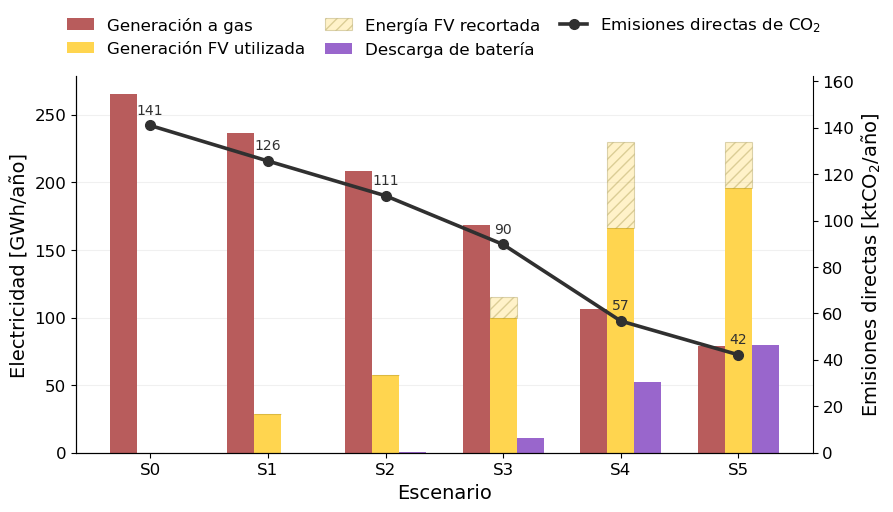

In [81]:
# ── v3. Figura PPT 1: impacto sistémico por escenario ──
ppt1_df = summary[summary["code"].astype(str).isin(PATHWAY_CODES)].copy()
ppt1_df["_order"] = ppt1_df["code"].astype(str).map({code: i for i, code in enumerate(PATHWAY_CODES)})
ppt1_df = ppt1_df.sort_values("_order")

etiquetas = ppt1_df["pathway_stage"].astype(str).tolist()
x = np.arange(len(etiquetas))
width = 0.23

gas_gwh = ppt1_df["thermal_generation_mwh"].to_numpy(dtype=float) / 1e3
solar_use_gwh = ppt1_df["solar_generation_mwh"].to_numpy(dtype=float) / 1e3
solar_curt_gwh = ppt1_df["solar_curtailment_mwh"].to_numpy(dtype=float) / 1e3
bess_gwh = ppt1_df["bess_discharge_mwh"].to_numpy(dtype=float) / 1e3
co2_kt = ppt1_df["co2_tons"].to_numpy(dtype=float) / 1e3

fig, ax = plt.subplots(figsize=(9, 5.8))
fig.patch.set_facecolor("white")

bar_gas = ax.bar(
    x - width,
    gas_gwh,
    width=width,
    color=PPT_COLORS["gas"],
    label="Generación a gas",
)
bar_solar = ax.bar(
    x,
    solar_use_gwh,
    width=width,
    color=PPT_COLORS["solar"],
    label="Generación FV utilizada",
)
bar_curt = ax.bar(
    x,
    solar_curt_gwh,
    bottom=solar_use_gwh,
    width=width,
    color=PPT_COLORS["solar"],
    alpha=0.30,
    hatch="///",
    edgecolor="#8a7a20",
    linewidth=0.8,
    label="Energía FV recortada",
)
bar_bess = ax.bar(
    x + width,
    bess_gwh,
    width=width,
    color=PPT_COLORS["bess"],
    label="Descarga de batería",
)

ax2 = ax.twinx()
ax2.set_ylim(bottom=0, top=max(co2_kt) * 1.15)
line_co2 = ax2.plot(
    x,
    co2_kt,
    color="#303030",
    marker="o",
    markersize=7,
    linewidth=2.6,
    label="Emisiones directas de CO$_2$",
)[0]

ax.set_xticks(x)
ax.set_xticklabels(etiquetas, fontsize=PPT_FONT_TICK)
ax.set_ylabel("Electricidad [GWh/año]", fontsize=PPT_FONT_AXIS)
ax2.set_ylabel("Emisiones directas [ktCO$_2$/año]", fontsize=PPT_FONT_AXIS)
ax.set_xlabel("Escenario", fontsize=PPT_FONT_AXIS)
#ax.set_title(
#    "Impacto sistémico de la adopción residencial de FV y baterías",
#    fontsize=PPT_FONT_TITLE,
#    fontweight="bold",
#    pad=12,
#)

ax.tick_params(axis="y", labelsize=PPT_FONT_TICK)
ax2.tick_params(axis="y", labelsize=PPT_FONT_TICK)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax2.spines["top"].set_visible(False)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    ncol=3,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.2),
    fontsize=PPT_FONT_LEGEND,
    columnspacing=1.2,
    handlelength=1.6,
)

for xi, yv in zip(x, co2_kt):
    ax2.annotate(
        f"{yv:.0f}",
        (xi, yv),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=10,
        color="#303030",
    )

fig.tight_layout(rect=[0, 0, 1, 0.92])
save_ppt_figure(fig, "cinvie_v3_figura1_sistema_ppt.png")
save_ppt_figure(fig, "cinvie_v3_figura1_sistema_ppt.svg")
plt.show()


Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura2_despacho_residencial_ppt.png
Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura2_despacho_residencial_ppt.svg


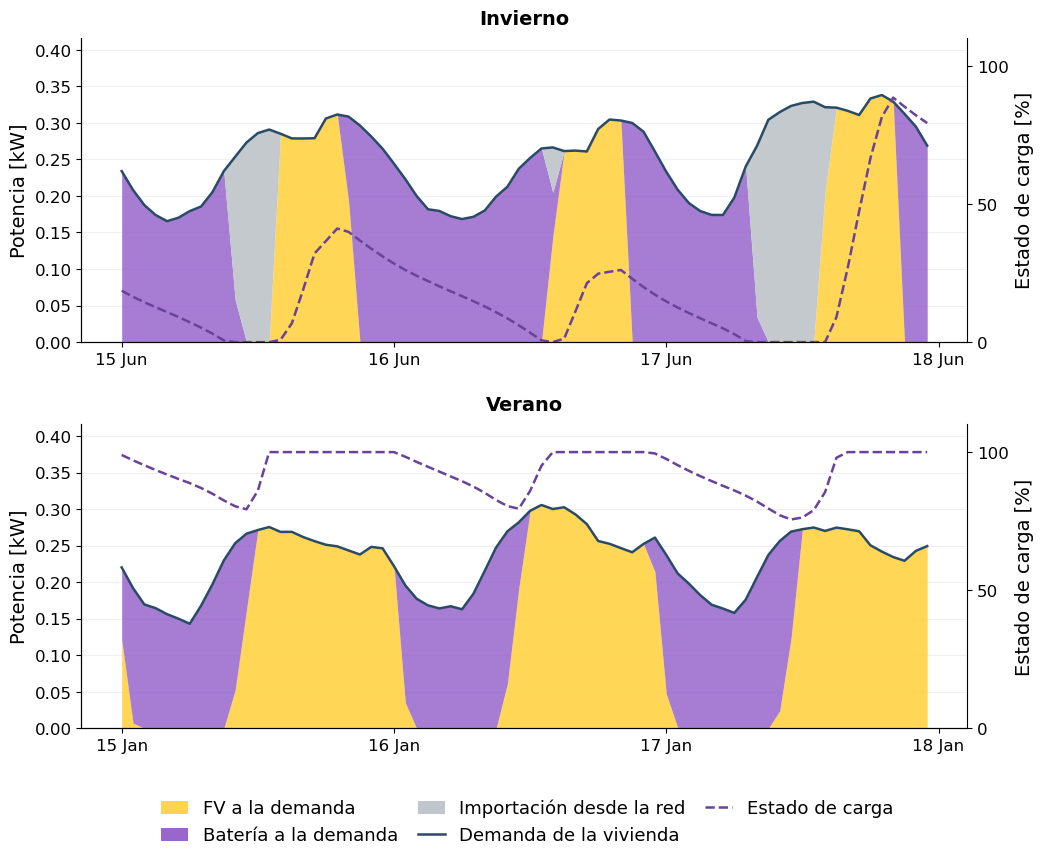

In [67]:
# ── v3. Figura PPT 2: despacho residencial representativo ──
fig, axes = plt.subplots(2, 1, figsize=(10.4, 8.2))
fig.patch.set_facecolor("white")

season_windows_es = [
    ("Invierno", f"{MODEL_YEAR}-06-15", f"{MODEL_YEAR}-06-17"),
    ("Verano", f"{MODEL_YEAR}-01-15", f"{MODEL_YEAR}-01-17"),
]
selected_windows = [btm_pvbess.loc[start:end] for _, start, end in season_windows_es]
common_ylim = max(0.1, *(float(df.load_kw.max()) for df in selected_windows)) * 1.23

for i, (ax, (titulo, _, _), h) in enumerate(zip(axes, season_windows_es, selected_windows)):
    x = h.index
    pv_to_load = h.pv_direct_kw.to_numpy()
    bess_to_load = h.bess_discharge_kw.to_numpy()
    grid_to_load = h.grid_import_kw.to_numpy()
    load_kw = h.load_kw.to_numpy()
    soc_pct = 100.0 * h.soc_end_kwh.to_numpy() / BESS_KWH_PER_HOME

    ax.fill_between(x, 0, pv_to_load, color=PPT_COLORS["solar"], alpha=0.96, linewidth=0)
    ax.fill_between(x, pv_to_load, pv_to_load + bess_to_load, color=PPT_COLORS["bess"], alpha=0.86, linewidth=0)
    ax.fill_between(x, pv_to_load + bess_to_load, pv_to_load + bess_to_load + grid_to_load, color=PPT_COLORS["grid"], alpha=0.95, linewidth=0)
    ax.plot(x, load_kw, color=PPT_COLORS["load"], linewidth=1.8)

    ax_soc = ax.twinx()
    ax_soc.plot(x, soc_pct, color=PPT_COLORS["soc"], linestyle="--", linewidth=1.8)
    ax_soc.set_ylim(0, 110)
    ax_soc.set_yticks([0, 50, 100])
    #if i == 1:
    ax_soc.set_ylabel("Estado de carga [%]", fontsize=PPT_FONT_AXIS)#, color=PPT_COLORS["soc"])
    ax_soc.tick_params(axis="y", labelsize=PPT_FONT_TICK)#, colors=PPT_COLORS["soc"])
    #else:
    #    ax_soc.tick_params(axis="y", right=False, labelright=False)
    ax_soc.spines["top"].set_visible(False)

    ax.set_title(titulo, fontsize=PPT_FONT_SUBTITLE, fontweight="bold", pad=10)
    ax.set_ylabel("Potencia [kW]", fontsize=PPT_FONT_AXIS)
    ax.set_ylim(0, common_ylim)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=PPT_FONT_TICK)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    #ax.text(
    #    0.995,
    #    1.03,
    #    f"FV: {h.pv_available_kw.sum():.1f} kWh  |  Carga batería: {h.bess_charge_kw.sum():.1f} kWh  |  Exportación: {h.grid_export_kw.sum():.1f} kWh  |  Importación: {h.grid_import_kw.sum():.1f} kWh",
    #    transform=ax.transAxes,
    #    ha="right",
    #    va="bottom",
    #    fontsize=10,
    #    color="0.35",
    #)

legend_handles = [
    plt.matplotlib.patches.Patch(facecolor=PPT_COLORS["solar"], label="FV a la demanda"),
    plt.matplotlib.patches.Patch(facecolor=PPT_COLORS["bess"], label="Batería a la demanda"),
    plt.matplotlib.patches.Patch(facecolor=PPT_COLORS["grid"], label="Importación desde la red"),
    plt.matplotlib.lines.Line2D([0], [0], color=PPT_COLORS["load"], linewidth=1.8, label="Demanda de la vivienda"),
    plt.matplotlib.lines.Line2D([0], [0], color=PPT_COLORS["soc"], linestyle="--", linewidth=1.8, label="Estado de carga"),
]

fig.legend(
    handles=legend_handles,
    ncol=3,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    fontsize=PPT_FONT_LEGEND+1,
    columnspacing=1.1,
    handlelength=1.5,
)
#fig.suptitle(
#    "Operación horaria de una vivienda representativa con FV + batería",
#    fontsize=PPT_FONT_TITLE,
#    fontweight="bold",
#    y=0.995,
#)
fig.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.3)
save_ppt_figure(fig, "cinvie_v3_figura2_despacho_residencial_ppt.png")
save_ppt_figure(fig, "cinvie_v3_figura2_despacho_residencial_ppt.svg")
plt.show()


C:\Users\vse23\AppData\Local\Temp\ipykernel_36460\4241488545.py:100: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura3_costos_resiliencia_ppt.png
Saved figure: output\output_punta_arenas_cinvie\figures\cinvie_v3_figura3_costos_resiliencia_ppt.svg


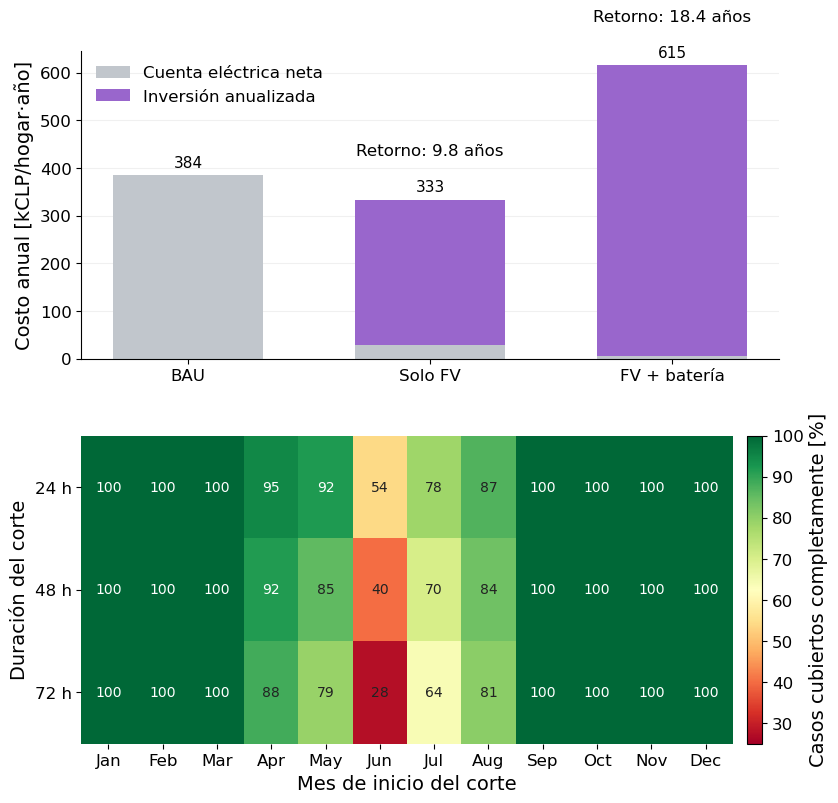

In [78]:
# ── v3. Figura PPT 3: costos privados y resiliencia ──
fig = plt.figure(figsize=(9, 9))
fig.patch.set_facecolor("white")
gs = fig.add_gridspec(2, 1, height_ratios=[0.8, 0.8], hspace=0.25)
ax_cost = fig.add_subplot(gs[0, 0])
ax_heat = fig.add_subplot(gs[1, 0])

# (a) Costos anuales equivalentes por tipo de vivienda.
econ_plot = btm_type_economic_breakdown.loc[["BAU", "PV only", "PV+BESS"]].copy()
econ_labels = ["BAU", "Solo FV", "FV + batería"]
x = np.arange(len(econ_plot))
net_bill = econ_plot["net_bill_clp_yr"].to_numpy(dtype=float) / 1000
annualised_capex = econ_plot["annualised_capex_clp_yr"].to_numpy(dtype=float) / 1000
annual_om = econ_plot["annual_om_clp_yr"].to_numpy(dtype=float) / 1000
total_cost = net_bill + annualised_capex + annual_om

ax_cost.bar(x, net_bill, width=0.62, color=PPT_COLORS["grid"], label="Cuenta eléctrica neta")
ax_cost.bar(x, annualised_capex, bottom=net_bill, width=0.62, color=PPT_COLORS["bess"], label="Inversión anualizada")
if np.any(annual_om > 0):
    ax_cost.bar(x, annual_om, bottom=net_bill + annualised_capex, width=0.62, color=PPT_COLORS["solar"], label="Operación y mantención")

for xi, total in zip(x, total_cost):
    ax_cost.text(xi, total + max(total_cost) * 0.018, f"{total:.0f}", ha="center", va="bottom", fontsize=11)

if "PV only" in btm_economics.index:
    pv_payback = float(btm_economics.loc["PV only", "simple_payback_years"])
    ax_cost.text(1, total_cost[1] + max(total_cost) * 0.15, f"Retorno: {pv_payback:.1f} años", ha="center", fontsize=12)#, color="b")
if "PV+BESS" in btm_economics.index:
    pvb_payback = float(btm_economics.loc["PV+BESS", "simple_payback_years"])
    ax_cost.text(2, total_cost[2] + max(total_cost) * 0.15, f"Retorno: {pvb_payback:.1f} años", ha="center", fontsize=12)#, color="b")

ax_cost.set_xticks(x)
ax_cost.set_xticklabels(econ_labels, fontsize=PPT_FONT_TICK)
ax_cost.set_ylabel("Costo anual [kCLP/hogar·año]", fontsize=PPT_FONT_AXIS)
#ax_cost.set_title("Costos privados por tipo de vivienda", fontsize=PPT_FONT_SUBTITLE, fontweight="bold", pad=10)
ax_cost.grid(axis="y", alpha=0.18)
ax_cost.set_axisbelow(True)
ax_cost.spines[["top", "right"]].set_visible(False)
ax_cost.tick_params(axis="y", labelsize=PPT_FONT_TICK)
ax_cost.legend(frameon=False, fontsize=PPT_FONT_LEGEND, loc="upper left")

# (b) Resiliencia mensual para la vivienda FV + batería.
monthly_outages_ppt = btm_outages.loc[
    btm_outages.system.eq("PV+BESS")
    & np.isclose(btm_outages.demand_fraction, 1.0)
    & btm_outages.outage_duration_h.isin([24, 48, 72])
].copy()
monthly_outages_ppt["month"] = monthly_outages_ppt.outage_start.dt.month
coverage = (
    monthly_outages_ppt.groupby(["outage_duration_h", "month"], as_index=False)
    .agg(full_service_pct=("full_service", lambda s: 100.0 * s.mean()))
    .pivot(index="outage_duration_h", columns="month", values="full_service_pct")
    .reindex(index=[24, 48, 72], columns=range(1, 13))
)

month_labels = [calendar.month_abbr[i] for i in range(1, 13)]
coverage_values = coverage.to_numpy(dtype=float)
vmin = max(0.0, float(np.floor((np.nanmin(coverage_values) - 1.0) / 5.0) * 5.0))
if vmin >= 100:
    vmin = 99.0
im = ax_heat.imshow(
    coverage_values,
    cmap="RdYlGn",
    origin="upper",
    aspect="auto",
    interpolation="nearest",
    vmin=vmin,
    vmax=100,
)
ax_heat.set_xticks(np.arange(12))
ax_heat.set_xticklabels(month_labels, fontsize=PPT_FONT_TICK)
ax_heat.set_yticks(np.arange(3))
ax_heat.set_yticklabels(["24 h", "48 h", "72 h"], fontsize=PPT_FONT_TICK)
ax_heat.set_xlabel("Mes de inicio del corte", fontsize=PPT_FONT_AXIS)
ax_heat.set_ylabel("Duración del corte", fontsize=PPT_FONT_AXIS)
#ax_heat.set_title("Resiliencia ante cortes de red (FV + batería)", fontsize=PPT_FONT_SUBTITLE, fontweight="bold", pad=10)
for row in range(coverage_values.shape[0]):
    for col in range(coverage_values.shape[1]):
        value = coverage_values[row, col]
        ax_heat.text(
            col,
            row,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=10,
            color="white" if value >= 90 else "#222222",
        )
ax_heat.spines[["top", "bottom", "left", "right"]].set_visible(False)
cb = fig.colorbar(im, ax=ax_heat, fraction=0.046, pad=0.02)
cb.ax.tick_params(labelsize=PPT_FONT_TICK)
cb.set_label("Casos cubiertos completamente [%]", fontsize=PPT_FONT_AXIS)

#fig.suptitle(
#    "Costos privados y beneficio de resiliencia a nivel residencial",
#    fontsize=PPT_FONT_TITLE,
#    fontweight="bold",
#    y=0.99,
#)
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_ppt_figure(fig, "cinvie_v3_figura3_costos_resiliencia_ppt.png")
save_ppt_figure(fig, "cinvie_v3_figura3_costos_resiliencia_ppt.svg")
plt.show()


In [79]:
summary.loc[summary["code"] == "BASE", ["peak_demand_mw", "demand_mwh"]]

,peak_demand_mw,demand_mwh
0,45.45725,277235.993344
